# Řevnice 2026: bayesovský odhad individuálních křížků ze 480 okrskových agregátů

**Komunální volby 9.–10. 10. 2026, město Řevnice (kód obce 539643), 15 mandátů, 8 kandidátek × 15 kandidátů, 4 volební okrsky, 23 939 platných kandidátských hlasů, 1 679 platných hlasovacích lístků (ČSÚ).**

Tento notebook odhaduje pro každého ze 120 kandidátů, kolik z jeho hlasů pochází z **individuálních křížků** (volič označil konkrétně jeho) a kolik z **mechanického přidělení** (volič zakřížkoval celou kandidátku). ČSÚ publikuje pouze součet obojího. Postup:

1. ověření dat a přesných pravidel sčítání (zákon č. 491/2001 Sb., metodika ČSÚ);
2. **model-free (rigorózní) dolní meze** – co lze dokázat bez jakéhokoli modelu, včetně nové, silnější meze plynoucí ze zákona zachování hlasů;
3. **hierarchický generativní bayesovský model** (PyMC 6 / ArviZ 1) s explicitní mechanikou lístků: rozdělení počtu křížků na lístcích se stranou, lístky bez strany, výhoda pozice, osobní popularita kandidátů, lokální okrskové odchylky, saturace „nejvýše jeden křížek pro kandidáta na lístku“;
4. prior predictive checks, **simulační test identifikovatelnosti** se známou pravdou, MCMC diagnostika, posterior predictive checks, citlivost na priory, leave-one-precinct-out;
5. výsledky pro kandidáty, kandidátky a okrsky, srovnání s rokem 2022 a s předchozím nebayesovským scénářovým modelem;
6. česky psaný souhrn zjištění s označením, co je **pozorovaný fakt**, **rigorózní dolní mez** a **modelový odhad**.

> **Zásadní upozornění.** Posteriorní odhady nejsou „změřené“ křížky. Jsou podmíněné modelem a priory. Agregovaná data (i po okrscích) v principu nerozlišují některé způsoby vyplnění lístku (Tam Cho & Gaines 2004). Tam, kde data parametry neurčují, to notebook explicitně ukazuje (simulační test, citlivost) a nabízí místo falešně přesného čísla dokazatelnou mez a rozpětí.

**Jak spustit:** `pip install -r requirements.txt`, pak `jupyter lab revnice_2026_bayesian_analysis.ipynb` a *Run All*. Vše běží lokálně, bez sítě. Plný běh (4 řetězce NUTS pro všech ~20 fitů) trvá na 2 jádrech cca 1,5–2 hodiny; `FAST = True` níže zkrátí řetězce (orientační výsledky za ~15 minut); `USE_CACHE = True` použije uložené fity ze složky `fits/`, pokud existují (vytvoří je `python scripts/run_all_fits.py`).

In [1]:
import os, sys, time, json, warnings, textwrap
from pathlib import Path
from dataclasses import replace
warnings.filterwarnings("ignore")

ROOT = Path.cwd() if (Path.cwd() / "src" / "revnice").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm, arviz as az, pytensor
from IPython.display import Markdown, display

from revnice import data as D, model as M, simulate as SIM, posterior as PO, analysis as A, plots as PL

FAST = os.environ.get("REVNICE_FAST", "0") == "1"       # kratší řetězce (orientační výsledky)
USE_CACHE = os.environ.get("REVNICE_USE_CACHE", "1") == "1"  # načíst uložené fity z fits/, pokud existují
SEED = 20261010
FITS, RES, FIG, INTER = ROOT / "fits", ROOT / "results", ROOT / "figures", ROOT / "interactive"
for p in (FITS, RES, FIG, INTER): p.mkdir(exist_ok=True)
PL.setup_style()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print(f"Python {sys.version.split()[0]} · PyMC {pm.__version__} · ArviZ {az.__version__} · PyTensor {pytensor.__version__} · numpy {np.__version__} · pandas {pd.__version__}")
print(f"FAST={FAST}, USE_CACHE={USE_CACHE}, ROOT={ROOT}")
MAIN_KW = dict(draws=300, tune=300, chains=4) if FAST else dict(draws=1000, tune=1000, chains=4)
SUB_KW  = dict(draws=150, tune=150, chains=4) if FAST else dict(draws=500, tune=500, chains=4)
REC_KW  = dict(draws=150, tune=150, chains=4) if FAST else dict(draws=600, tune=600, chains=4)

import re
def czfmt(text: str) -> str:
    # České formátování čísel v textu: tisíce mezerou, desetinná čárka, mezera před %
    text = re.sub(r"(?<![\d.])(\d{1,3})((?:,\d{3})+)(?!\d)", lambda m: m.group(1) + m.group(2).replace(",", "\u202f"), text)
    text = re.sub(r"(\d)\.(\d)", r"\1,\2", text)
    text = re.sub(r"(\d)%(?! interval| klauzul| credible)", "\\1\u202f%", text)
    return text

def fit_or_load(name, build, **kw):
    fn = FITS / f"{name}.nc"
    if USE_CACHE and fn.exists():
        print(f"[cache] {fn.name}"); return az.from_netcdf(fn)
    t0 = time.time(); idata = M.sample(build(), seed=SEED, **kw)
    print(f"[fit] {name}: {time.time()-t0:.0f} s"); idata.to_netcdf(fn); return idata

Python 3.13.16 · PyMC 6.3.2 · ArviZ 1.3.0 · PyTensor 3.3.3 · numpy 2.5.3 · pandas 3.0.5
FAST=False, USE_CACHE=False, ROOT=/home/claude/revnice2026-bayes


## 1. Pravidla hlasování a sčítání (ověřeno z oficiálních zdrojů)

Mechanika je klíčová, protože určuje, co je v datech vůbec vidět. Pravidla jsme ověřili ve dvou oficiálních zdrojích:

* **Portál veřejné správy**, rozcestník *Volby do zastupitelstev obcí* (https://portal.gov.cz/rozcestniky/RZC-118): volič „označí křížkem čtverec vedle názvu politické strany“ *nebo* „označí křížkem vedle jmen kandidátů osoby, pro které hlasuje“ (nejvýše tolik, kolik se volí členů zastupitelstva), *nebo* „označí křížkem některou stranu a zároveň označí i několik kandidátů jiných stran“ – označená strana pak přijde „zdola o tolik hlasů, kolik volič zvolil kandidátů z jiné strany“.
* **ČSÚ, *Volby do zastupitelstev obcí – vyhodnocení hlasů* (říjen 2026)**, https://volby.gov.cz/prg/zo26_priklady_vyhodnoceni_hl_pro_tisk.pdf, s odkazy na § 34 odst. 1–3, § 40 odst. 2 a § 41 zákona č. 491/2001 Sb.: „hlasy získávají kandidáti označené volební strany v pořadí podle hlasovacího lístku“; při kombinaci „hlasy získávají nejprve označení kandidáti jiných volebních stran než označené strany“ a zbývající hlasy připadnou kandidátům označené strany „podle pořadí na hlasovacím lístku“; „u označené volební strany se již nepřihlíží k označeným kandidátům této volební strany“; lístek je neplatný, „je-li označena více než jedna volební strana“ nebo „je-li označeno více kandidátů, než kolik se v obci volí zastupitelů“.

Plné znění zákona č. 491/2001 Sb. (zakonyprolidi.cz) se v tomto prostředí nepodařilo stáhnout; citujeme proto metodický dokument ČSÚ, který paragrafy přímo uvádí. Důsledky pro data (15 mandátů, všechny kandidátky plné):

| typ lístku | kandidáti označené strany | ostatní označení kandidáti | hlasů celkem z lístku |
|---|---|---|---|
| jen strana | prvních 15 po 1 hlasu | – | **15** |
| strana + $k$ kandidátů jiných stran ($1\le k\le 14$) | prvních $15-k$ po 1 hlasu | $k$ × 1 hlas | **15** |
| strana + 15 kandidátů jiných stran | nic | 15 × 1 hlas | 15 (nerozlišitelné od lístku bez strany) |
| jen kandidáti ($1\le m\le 15$) | – | $m$ × 1 hlas | $m \le 15$ |

Dvě pozorování, která nesou celou identifikaci: **(a)** stranicky přidělené hlasy jsou **nerostoucí** s pořadím na kandidátce (nižší místa přicházejí o hlasy jako první); **(b)** lístek se stranou vytvoří **přesně 15 hlasů**, lístek bez strany **nejvýše 15** – zákon zachování, který spojuje počet lístků s počtem hlasů.

**Literatura k metodě.** Tam Cho, W. K. & Gaines, B. J. (2004): *The Limits of Ecological Inference: The Case of Split-Ticket Voting*, American Journal of Political Science 48(1), 152–171, DOI 10.1111/j.0092-5853.2004.00062.x – „We show that the estimation technique is highly suspect in general and especially unhelpful with their particular data.“ (agregáty obecně neidentifikují chování jednotlivců). Park, W.-h., Hanmer, M. J. & Biggers, D. R. (2014): *Ecological inference under unfavorable conditions: Straight and split-ticket voting in diverse settings and small samples*, Electoral Studies 36, 192–203, DOI 10.1016/j.electstud.2014.08.006 – „The estimator also performs well even when the number of aggregate units is quite small“ (ale s desítkami jednotek; my máme 4 okrsky). Kaňok, D.: *Analýza preferenčního hlasování ve volbách do zastupitelstev obcí v letech 2006–2018* (theses.cz/id/id9d17) – stránku se v tomto prostředí nepodařilo načíst, obsah proto necitujeme. Bayesovský workflow: Gelman et al. (2020) *Bayesian Workflow*, arXiv:2011.01808; Gabry et al. (2019) *Visualization in Bayesian workflow*, JRSS A 182(2), DOI 10.1111/rssa.12378; Vehtari et al. (2021) *Rank-normalization, folding, and localization: An improved R̂*, Bayesian Analysis 16(2), DOI 10.1214/20-BA1221; Talts et al. (2018) *Validating Bayesian inference algorithms with simulation-based calibration*, arXiv:1804.06788. Software: PyMC (Abril-Pla et al. 2023, PeerJ CS 9:e1516, DOI 10.7717/peerj-cs.1516), ArviZ (Kumar et al. 2019, JOSS 4(33):1143, DOI 10.21105/joss.01143).

## 2. Data a kontrolní součty

Vstupy jsou 32 CSV exportů z volby.gov.cz (4 okrsky × 8 kandidátek), sloučené skriptem `scripts/prepare_and_validate.py` do `data/processed/precinct_candidates_2026.csv` (480 řádků) a `city_candidates_2026.csv` (120 řádků). Soubory jsou UTF-8 s BOM, oddělovač `;`. Níže znovu ověříme všechny kontrolní součty (shoda okrsků s městským exportem, součty stran, okrsků i celku).

In [2]:
import subprocess
out = subprocess.run([sys.executable, "-I", str(ROOT / "scripts" / "prepare_and_validate.py")], capture_output=True, text=True, cwd=ROOT)
print(out.stdout[:600]); assert "VALIDATION PASSED" in out.stdout, out.stderr

d = D.load()
H = d.H                      # (4 okrsky, 8 kandidátek, 15 pozic)
assert H.shape == (4, 8, 15) and H.sum() == 23939
assert list(d.precinct_votes) == [5778, 6012, 5818, 6331]
assert list(d.party_votes) == [4840, 1630, 5553, 1102, 2498, 1182, 4683, 2451]
city = d.city.set_index(["party_id", "position"])
for s in range(8):
    for i in range(15):
        assert H[:, s, i].sum() == city.loc[(s + 1, i + 1), "votes"]
V_CITY = 1679   # platné hlasovací lístky (ČSÚ, vysledky_obec_539643.xml, generováno 2026-10-10 19:12; zapsaní voliči 2 819, vydané obálky 1 690, účast 59,95 %)
print("Kontrolní součty v pořádku: 480 pozorování, 23 939 hlasů, 4 okrsky, 8 kandidátek, 120 kandidátů.")
print(f"Platné lístky (ČSÚ): {V_CITY} → průměr {23939 / V_CITY:.2f} hlasu na lístek, nevyužito {15 * V_CITY - 23939} z {15 * V_CITY} možných hlasů.")
MANDATES = {1: 3, 2: 1, 3: 4, 4: 0, 5: 2, 6: 0, 7: 3, 8: 2}
parties = d.parties_2022_2026.copy(); parties["mandáty 2026"] = parties["strana"].map({D.PARTY_FULL[k]: v for k, v in MANDATES.items()}).fillna(0).astype(int)
parties["práh 5 % (hlasů)"] = np.where(parties["hlasy_2026"] > 0, np.ceil(0.05 * 23939), np.nan)
display(parties)

VALIDATION PASSED
Files: 32, precinct candidate observations: 480, candidates: 120, total votes: 23939
Party totals:
 1 ŠANCE Řevnice: 4840
 2 TOP 09 a nezávislí kandidáti: 1630
 3 DOBŘE - Dialog o budoucnosti Řevnic: 5553
 4 Hnutí Srdce Řevnic: 1102
 5 PRO Řevnice: 2498
 6 ODS a nezávislí: 1182
 7 Perspektiva pro město: 4683
 8 Naše Řevnice: 2451
Precinct candidate vote totals: {1: 5778, 2: 6012, 3: 5818, 4: 6331}
Exact minimum city-only: 1096
Exact minimum with precinct observations: 1493
Terezie Červená:
 precinct 1 votes 103 minimum 17
 precinct 2 votes 96 minimum 21
 precinct 3 votes 102 
Kontrolní součty v pořádku: 480 pozorování, 23 939 hlasů, 4 okrsky, 8 kandidátek, 120 kandidátů.
Platné lístky (ČSÚ): 1679 → průměr 14.26 hlasu na lístek, nevyužito 1246 z 25185 možných hlasů.


,strana,hlasy_2022,podil_2022_pct,hlasy_2026,podil_2026_pct,zmena_hlasu,zmena_p_b,mandáty 2026,práh 5 % (hlasů)
0,ŠANCE Řevnice,4828,22.17,4840,20.22,12,-1.96,3,"1,197.00"
1,TOP 09 a nezávislí kandidáti,1551,7.12,1630,6.81,79,-0.31,1,"1,197.00"
2,DOBŘE - Dialog o budoucnosti Řevnic,0,0.00,5553,23.20,5553,23.20,4,"1,197.00"
3,Hnutí Srdce Řevnic,1244,5.71,1102,4.60,-142,-1.11,0,"1,197.00"
4,PRO Řevnice,3014,13.84,2498,10.43,-516,-3.41,2,"1,197.00"
5,ODS a nezávislí,1519,6.98,1182,4.94,-337,-2.04,0,"1,197.00"
6,Perspektiva pro město,5783,26.56,4683,19.56,-1100,-7.00,3,"1,197.00"
7,Naše Řevnice,2632,12.09,2451,10.24,-181,-1.85,2,"1,197.00"
8,Řevnice SPOLEČNĚ,1202,5.52,0,0.00,-1202,-5.52,0,NaN


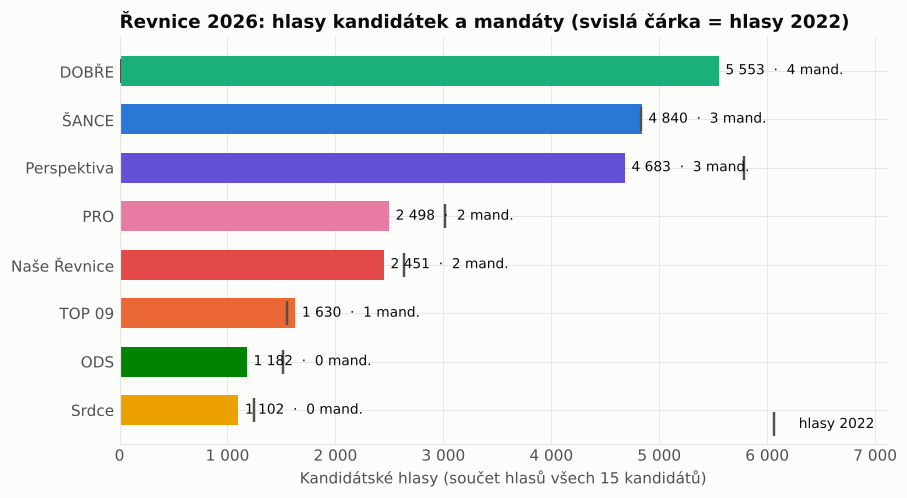

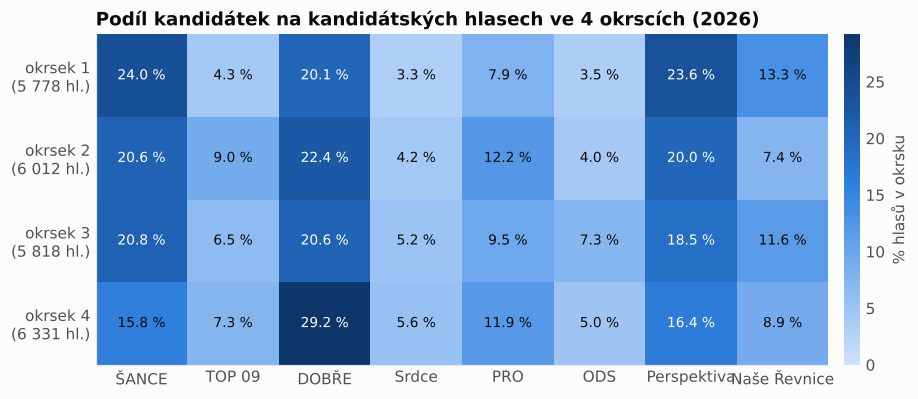

In [3]:
fig = PL.fig_parties(d, MANDATES); plt.show()
fig = PL.fig_precinct_heatmap(d); plt.show()

**Pozorované fakty:** ODS a nezávislí získali 1 182 hlasů = 4,94 %; uzavírací klauzule 5 % z 23 939 platných hlasů činí 1 197 hlasů – ODS chybělo **15 hlasů, tj. přesně jeden lístek se zakřížkovanou stranou**, aby se vůbec podílela na rozdělení mandátů (§ 45 zákona č. 491/2001 Sb.). Hnutí Srdce Řevnic (4,60 %) chybělo 95 hlasů. Okrsek 4 je jediný, kde DOBŘE výrazně vede (29,2 %); bez něj by bylo pořadí ŠANCE – DOBŘE – Perspektiva těsné (aritmetika, ne kauzalita).

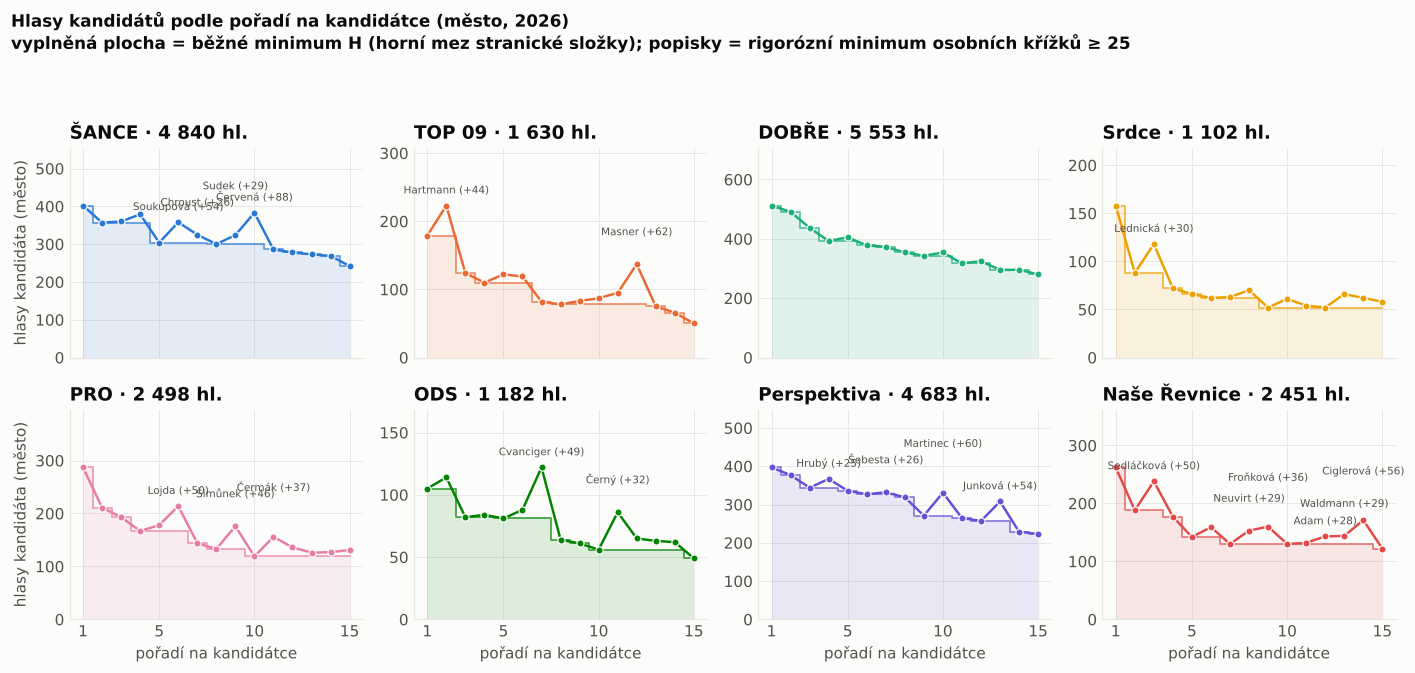

In [4]:
bounds = D.bounds_table(d)
fig = PL.fig_candidate_profiles(d, bounds); plt.show()

## 3. Co lze dokázat bez modelu: rigorózní dolní meze

Pro kandidáta na pořadí $i$ kandidátky $s$ v okrsku $p$ platí

$$H_{p,s,i} = S_{p,s,i} + C_{p,s,i},\qquad S_{p,s,1}\ge S_{p,s,2}\ge\dots\ge S_{p,s,15}\ge 0,\qquad C_{p,s,i}\ge 0,$$

kde $S$ jsou hlasy přidělené mechanicky z lístků s označenou stranou a $C$ efektivní individuální křížky (z lístků s jinou stranou i z lístků bez strany). Protože $S_{p,s,i}\le\min_{j\le i} S_{p,s,j}\le\min_{j\le i}H_{p,s,j}$, dostáváme **přesnou nerovnost**

$$C_{p,s,i}\;\ge\;\max\Bigl(0,\;H_{p,s,i}-\min_{j\le i}H_{p,s,j}\Bigr).$$

Součet těchto mezí přes okrsky je silnější než mez z městských součtů (minimum se bere v každém okrsku zvlášť).

**Nová, silnější mez pro celek (lineární program).** Z pravidla „lístek se stranou vytvoří přesně 15 hlasů, lístek bez strany nejvýše 15“ plyne pro počet efektivně označených stran v okrsku $B_{p,s}=S_{p,s,1}$:

$$\sum_s B_{p,s}\;\le\;\frac{H^{\text{tot}}_p}{15}.$$

Minimalizujeme-li $\sum_{s,i} C_{p,s,i}=H^{\text{tot}}_p-\sum_{s,i}S_{p,s,i}$ za podmínek monotonie, $S\le H$ a této nerovnosti, dostaneme dokazatelnou dolní mez celkového počtu individuálních křížků v okrsku (LP, řešeno HiGHS). Nejde o odhad, ale o důsledek pravidel sčítání. Pro jednotlivé kandidáty se tato vazba neprojeví (ostatní strany lze v LP „vynulovat“), pro součty ano – např. $\sum_s C_{p,s,i}\ge\sum_s H_{p,s,i}-H^{\text{tot}}_p/15$ pro každé pořadí $i$.

In [5]:
lb_prec = D.rigorous_lower_bound(H); lb_city = D.rigorous_lower_bound(d.H_city)
lp = [D.lp_total_lower_bound(H[p]) for p in range(4)]
lp_city = D.lp_total_lower_bound(d.H_city)
LB_MONO_CITY, LB_MONO_PREC, LB_LP = int(lb_city.sum()), int(lb_prec.sum()), int(np.ceil(sum(r["min_total_C"] for r in lp)))
assert (LB_MONO_CITY, LB_MONO_PREC) == (1096, 1493)
cerv = bounds[bounds.name.str.contains("Červená")].iloc[0]
assert (cerv.lb_city, cerv.lb_precinct_sum) == (83, 88)
pos_sum = np.array([D.position_sum_lower_bound(H[p]) for p in range(4)])
display(Markdown(czfmt(f'''
| mez | hodnota | poznámka |
|---|---:|---|
| monotonie, městské součty | **{LB_MONO_CITY:,}** | odpovídá zadání (1 096) |
| monotonie, součet přes 4 okrsky | **{LB_MONO_PREC:,}** | odpovídá zadání (1 493); Terezie Červená {cerv.lb_city} → {cerv.lb_precinct_sum} ({cerv.lb_p1}+{cerv.lb_p2}+{cerv.lb_p3}+{cerv.lb_p4}) |
| LP se zákonem zachování, městské součty | **{int(np.ceil(lp_city["min_total_C"])):,}** | nová mez |
| LP se zákonem zachování, součet přes okrsky | **{LB_LP}** ({LB_LP/23939:.1%} všech hlasů) | nová mez; po okrscích: {", ".join(str(int(np.ceil(r["min_total_C"]))) for r in lp)} |
| max. počet lístků se stranou (k ≤ 14) | {", ".join(f"{r['max_party_ballots']:.0f}" for r in lp)} | = hlasy okrsku / 15 |
| mez pro součet křížků lídrů (pořadí 1) | {int(pos_sum[:, 0].sum())} | lídři všech stran dohromady |
''')))
bounds.to_csv(RES / "rigorous_bounds_candidates.csv", index=False, sep=";", encoding="utf-8-sig")
pd.DataFrame({"precinct": range(1, 5), "votes": d.precinct_votes, "max_party_ballots": [r["max_party_ballots"] for r in lp],
              "lb_monotone": lb_prec.sum(axis=(1, 2)), "lb_lp_conservation": [np.ceil(r["min_total_C"]) for r in lp]}).to_csv(RES / "rigorous_bounds_precincts.csv", index=False, sep=";", encoding="utf-8-sig")
top_lb = bounds.sort_values("lb_precinct_sum", ascending=False).head(12)[["party", "position", "name", "votes", "lb_city", "lb_precinct_sum", "lb_p1", "lb_p2", "lb_p3", "lb_p4"]]
display(top_lb.reset_index(drop=True))


| mez | hodnota | poznámka |
|---|---:|---|
| monotonie, městské součty | **1 096** | odpovídá zadání (1 096) |
| monotonie, součet přes 4 okrsky | **1 493** | odpovídá zadání (1 493); Terezie Červená 83 → 88 (17+21+28+22) |
| LP se zákonem zachování, městské součty | **2 529** | nová mez |
| LP se zákonem zachování, součet přes okrsky | **2890** (12,1 % všech hlasů) | nová mez; po okrscích: 646, 776, 708, 761 |
| max. počet lístků se stranou (k ≤ 14) | 385, 401, 388, 422 | = hlasy okrsku / 15 |
| mez pro součet křížků lídrů (pořadí 1) | 706 | lídři všech stran dohromady |


,party,position,name,votes,lb_city,lb_precinct_sum,lb_p1,lb_p2,lb_p3,lb_p4
0,ŠANCE,10,Červená Terezie Ing.,383,83,88,17,21,28,22
1,TOP 09,12,Masner Ondřej MUDr.,137,59,62,12,14,19,17
2,Perspektiva,10,Martinec Šimon Ing.,331,60,60,9,19,13,19
3,Naše Řevnice,14,Ciglerová Barbora Bc.,171,41,56,14,18,10,14
4,ŠANCE,6,Soukupová Květa Ing.,358,54,54,16,12,16,10
5,Perspektiva,13,Junková Ivana MgA.,308,51,54,9,24,9,12
6,PRO,6,Lojda Jan Ing. Ph.D.,214,47,50,11,22,11,6
7,Naše Řevnice,3,Sedláčková Davidová Markéta,238,50,50,17,17,5,11
8,ODS,7,Cvanciger Miroslav Bc.,122,41,49,8,3,16,22
9,PRO,9,Šimůnek Jan Ing.,176,43,46,17,6,9,14


**Rigorózní dolní mez** celkového počtu individuálních křížků se zákonem zachování je tedy výrazně vyšší než prostý součet monotónních mezí – a to čistě z pravidel sčítání. Protože známe i počet platných lístků (1 679), víme navíc, že voliči nevyužili 1 246 z 25 185 možných hlasů; nevyužité hlasy vznikají **pouze** na lístcích bez označené strany, takže těchto lístků bylo nejméně 1 246/14 ≈ 89 a jejich průměrný počet křížků $\bar m$ určuje jejich počet: $M = 1246/(15-\bar m)$. Tuto vazbu model používá.

## 4. Generativní hierarchický model

### 4.1 Mechanická (stranická) složka
Pro voliče kandidátky $s$ nechť $K\in\{0,\dots,14\}$ je počet křížků u kandidátů *jiných* stran, $\pi_{s,k}=P(K=k)$ (lístky s $K=15$ jsou nerozlišitelné od lístků bez strany a zahrnujeme je tam). Je-li $B_{p,s}$ počet takových lístků v okrsku, pak

$$S_{p,s,i}=B_{p,s}\,q_{s,i},\qquad q_{s,i}=P(K\le 15-i)=\sum_{k=0}^{15-i}\pi_{s,k}.$$

$\pi_s$ je hierarchické (logistic-normal): $\boldsymbol\pi_s=\mathrm{softmax}(\boldsymbol\eta_0+\sigma_\eta \mathbf z_s)$, $\eta_{0,k}\sim\mathcal N(\log w_k, 1)$, kde $w$ má $P(K=0)=0{,}5$ a geometricky klesající ocas (poměr 0,7) **bez useknutí** – extrémní $k$ jsou apriorně vzácná, ne zakázaná. Priory $P(K=0)$ a tvaru ocasu jsou předmětem citlivostní analýzy.

### 4.2 Zákon zachování a lístky bez strany
S počtem platných lístků $V$ (ČSÚ) a $\bar m$ = průměrný počet křížků na lístku bez strany:

$$M=\frac{15V-H^{\text{tot}}}{15-\bar m},\qquad R=\bar m M,\qquad \sum_{p,s}B_{p,s}=V-M,\qquad R_p=R\,r_p,\; \mathbf r\sim\mathrm{Dir}(2),\qquad \sum_s B_{p,s}=\frac{H^{\text{tot}}_p-R_p}{15},$$

$B_{p,\cdot}$ se dělí mezi strany Dirichletovým podílem $\mathbf g_p\sim\mathrm{Dir}(1)$. Prior $(\bar m-1)/(\bar m_{\max}-1)\sim\mathrm{Beta}(2,2)$, $\bar m_{\max}=H^{\text{tot}}/V=14{,}26$. **Toto je substantivní, slabě identifikovaný předpoklad** (viz citlivost).

### 4.3 Individuální (osobní) složka – alokace křížků
Každý křížek v okrsku $p$ připadne kandidátovi $(s,i)$ s vahou

$$w_{p,s,i}\propto\exp\bigl(a_s+e_{p,s}+\theta_i+u_{s,i}+v_{p,s,i}\bigr),\qquad \theta_i=-\beta\log i+\psi_i,$$

kde $a_s\sim\mathcal N(0,\sigma_a)$ je osobní přitažlivost kandidátky, $e_{p,s}\sim\mathcal N(0,\sigma_e)$ její okrsková odchylka, $\theta_i$ **výhoda pozice pro křížky** (log-lineární sklon $\beta\sim\mathcal N(0{,}7;0{,}5)$ s hladkými odchylkami $\psi_i\sim\mathcal N(0,\sigma_\psi)$, $\psi_1=0$) – oddělená od mechanického $q_{s,i}$, $u_{s,i}\sim\mathcal N(0,\sigma_u)$ **osobní popularita kandidáta sdílená napříč okrsky** a $v_{p,s,i}\sim\mathcal N(0,\sigma_v)$ lokální (okrsková) popularita. Všechny $\sigma\sim\mathrm{HalfNormal}$, parametrizace non-centered.

Křížky voličů strany $s'$ jdou jen mimo $s'$ (váhy renormalizované), lístky bez strany na kohokoli. Protože **kandidát může z jednoho lístku dostat nejvýše jeden hlas**, volič s $m$ křížky vybírá $m$ *různých* kandidátů; pravděpodobnost výběru aproximujeme poissonizací $p_c=1-\exp(-m\lambda w_c)$ s $\lambda$ voleným tak, aby $\sum_c p_c=m$ (pro lístky bez strany pevný bod, pro $k\le 14$ korekce prvního řádu). Očekávané křížky:

$$\mu^C_{p,s,i}= M_p\,p^{\text{pure}}_{p,(s,i)} + \sum_{s'\ne s} B_{p,s'}\sum_{k=1}^{14}\pi_{s',k}\,p^{(k)}_{p,s',(s,i)} .$$

Součty respektují zachování: $\sum_{s,i}(S+\mu^C)_{p,s,i}=H^{\text{tot}}_p$.

### 4.4 Likelihood
$S_{p,s,i}$ je součet multinomiálních počtů $N_{p,s,k}$, takže $\mathrm{Var}(S_{p,s,i})=B_{p,s}q_{s,i}(1-q_{s,i})$; $C$ je součet Bernoulliho pokusů, $\mathrm{Var}\approx\mu^C$. Používáme normální aproximaci s **mechanistickým rozptylem**

$$H_{p,s,i}\sim\mathcal N\bigl(S_{p,s,i}+\mu^C_{p,s,i},\;B_{p,s}q_{s,i}(1-q_{s,i})+\mu^C_{p,s,i}+(\varphi\,\mu)^2+0{,}5\bigr),\qquad \varphi\sim\mathrm{HalfNormal}(0{,}05),$$

kde $\varphi$ je dodatečná (nemechanická) overdisperze. Alternativy (Poisson; vícerozměrná normální s přesnou kovariancí multinomiálních součtů uvnitř bloku) jsou implementovány a porovnány v citlivosti.

### 4.5 Co je aproximace a proč
* **Očekávané hodnoty místo vzorkování lístků:** $S$ a $\mu^C$ jsou intenzity, ne realizované celočíselné počty; realizované $C$ získáme až podmíněně na $H$ (odd. 7) a vždy v mezích $[\text{rigorózní minimum},H]$.
* **Poissonizace výběru bez vracení** a společné $\bar m$ pro všechny okrsky.
* **Neznámý rozpis lístků po okrscích** ($V_p$ ČSÚ v balíčku není; používáme městský součet a Dirichletův rozpis $R_p$).
* Rozdělení $K$ je společné pro okrsky (liší se jen mezi stranami).
* Posteriorní interval je **podmíněný těmito předpoklady**; nestíráme rozdíl mezi credible intervalem, scénářovým rozpětím (citlivost), predikčním intervalem (PPC) a rigorózní mezí.

### 4.6 Identifikovatelnost – intuice
Uvnitř bloku je $H_i=B q_i+\lambda c_i$: stranická složka je **plochá vpředu a klesá až na konci** (podle ocasu $K$), osobní složka **klesá od začátku** (výhoda pozice) a je **společná pro 4 okrsky** ($u_{s,i}$). Co data *nerozliší*: osobní křížky rozprostřené rovnoměrně po celé kandidátce vypadají jako stranické lístky (volič, který zakřížkuje všech 15 lidí jedné strany, je v agregátu totožný s voličem strany). Proto je celkový počet křížků identifikován jen slabě (přes $\bar m$ a zachování), zatímco **relativní osobní efekty $u_{s,i}$ a pořadí kandidátů** jsou identifikovány dobře – což ověří simulace v oddíle 6.

In [6]:
import inspect
print(inspect.getsource(M.PriorConfig))

@dataclass
class PriorConfig:
    """Všechny apriorní volby na jednom místě (pro citlivostní analýzu)."""

    # --- rozdělení K (počet křížků u jiných stran na stranickém lístku) ---
    p0_mean: float = 0.5  # apriorní střed P(K=0)
    tail_ratio: float = 0.70  # geometrický pokles P(K=k+1)/P(K=k) pro k>=1 (bez useknutí)
    k_logit_sd: float = 1.0  # šířka prioru logitů pi0 (po kategoriích)
    sigma_eta_sd: float = 0.5  # HalfNormal: kolik se K-rozdělení liší mezi stranami
    # --- rozklad hlasů okrsku na stranické lístky a čistě osobní křížky ---
    g_alpha_party: float = 1.0  # Dirichlet koncentrace pro 8 stran
    g_alpha_pure: float = 1.0  # Dirichlet koncentrace pro "čistě osobní" složku R (bez V)
    n_valid_ballots: float | None = 1679  # platné lístky v celém městě (ČSÚ); None = nepoužít
    mbar_beta: tuple = (2.0, 2.0)  # Beta prior pro (m̄-1)/(m̄_max-1): průměrný počet křížků na lístku bez strany
    r_split_alpha: float = 2.0  # Dirichlet: rozdělení čistých křížků mez

In [7]:
print(inspect.getsource(M.build_model))

def build_model(H: np.ndarray, cfg: PriorConfig | None = None) -> pm.Model:
    """Sestaví PyMC model pro pole hlasů ``H`` tvaru (P, 8, 15).

    ``H`` může mít méně než 4 okrsky (použito v leave-one-precinct-out).
    """
    cfg = cfg or PriorConfig()
    H = np.asarray(H, dtype=int)
    P, S_, I_ = H.shape
    assert S_ == N_PARTIES and I_ == N_POS
    positions = np.arange(1, N_POS + 1)
    H_tot = H.sum(axis=(1, 2)).astype(float)  # (P,)
    H1 = H[:, :, 0].astype(float)
    kvals = np.arange(N_POS, dtype=float)
    offdiag = 1.0 - np.eye(N_PARTIES)  # [s, s'] = 1 pokud s != s'

    coords = {
        "precinct": np.arange(1, P + 1),
        "party": np.arange(1, N_PARTIES + 1),
        "position": positions,
        "k": np.arange(0, N_POS),
        "cell": [f"party{s}" for s in range(1, 9)] + ["pure"],
    }
    with pm.Model(coords=coords) as model:
        # ---------------- K-rozdělení (hierarchické, logistic-normal) -------------
        eta0 = pm.Normal("eta0", mu=cfg.k_pri

In [8]:
cfg = M.PriorConfig(n_valid_ballots=V_CITY)
json.dump(cfg.to_dict(), open(RES / "prior_config_main.json", "w"), indent=2, ensure_ascii=False)
model_main = M.build_model(H, cfg)
n_free = sum(int(np.prod(v.shape.eval())) for v in model_main.free_RVs)
print(f"Volných parametrů: {n_free}; pozorování: 480")
display(pd.DataFrame(cfg.to_dict().items(), columns=["prior / volba", "hodnota"]))

Volných parametrů: 834; pozorování: 480


,prior / volba,hodnota
0,p0_mean,0.50
1,tail_ratio,0.70
2,k_logit_sd,1.00
3,sigma_eta_sd,0.50
4,g_alpha_party,1.00
5,g_alpha_pure,1.00
6,n_valid_ballots,1679
7,mbar_beta,"(2.0, 2.0)"
8,r_split_alpha,2.00
9,sigma_a_sd,1.00


## 5. Prior predictive checks

Z priorů generujeme hypotetická data a ověřujeme, že prior pokrývá pozorované měřítko (celkové hlasy jsou v tomto modelu zachovány konstrukcí, zajímavý je tvar profilů a poměr posledního a prvního místa).

Sampling: [H, beta, eta0, g, mbar_frac, phi, r_split, sigma_a, sigma_e, sigma_eta, sigma_psi, sigma_u, sigma_v, z_a, z_e, z_eta, z_psi, z_u, z_v]


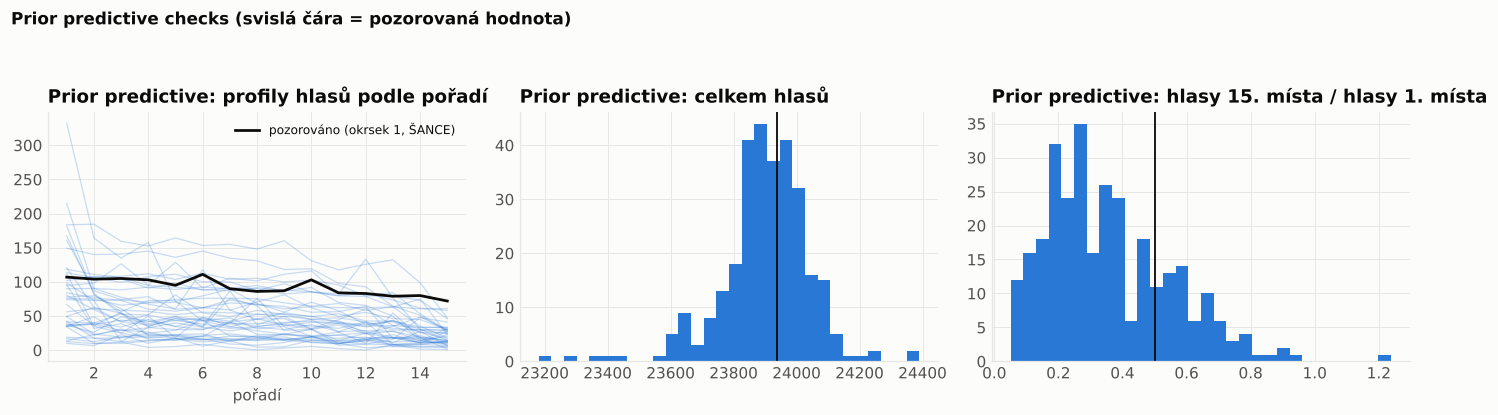

Poměr hlasů 15. a 1. místa: pozorováno 0.502; prior predictive 5–95 %: 0.095–0.711


In [9]:
prior_H = A.prior_predictive(H, cfg, n=300, seed=SEED)
fig = PL.fig_prior_predictive(prior_H, d); plt.show()
ratio_obs = H[:, :, 14].sum() / H[:, :, 0].sum()
ratio_pp = prior_H[:, :, :, 14].sum(axis=(1, 2)) / prior_H[:, :, :, 0].sum(axis=(1, 2))
print(f"Poměr hlasů 15. a 1. místa: pozorováno {ratio_obs:.3f}; prior predictive 5–95 %: {np.quantile(ratio_pp, 0.05):.3f}–{np.quantile(ratio_pp, 0.95):.3f}")

## 6. Simulační test identifikovatelnosti (známá pravda)

`revnice.simulate` generuje **jednotlivé hlasovací lístky** podle skutečných pravidel (strana; strana + $k$ různých kandidátů jiných stran; jen kandidáti; sčítání jako okrsková komise) s velikostí jako v Řevnicích (400–440 lístků na okrsek). Známe pak pravé $C$, $S$, $N$ i pravé parametry. Scénáře:

* **A – málo křížků:** $P(K=0)=0{,}75$, krátký ocas, 6 % lístků bez strany;
* **B – hodně křížků:** $P(K=0)=0{,}40$, dlouhý ocas, 20 % lístků bez strany;
* **D – strany se liší:** $P(K=0)$ od 0,40 do 0,80 podle strany, 10 % lístků bez strany.

Model dostane pouze $H$ a počet lístků. Sledujeme pokrytí 90% intervalů, korelaci a vychýlení odhadů $C$ po kandidátech, obnovu pořadí, $P(K=0)$, $\beta$, $\sigma_u$ a celkového počtu křížků.

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [eta0, sigma_eta, z_eta, mbar_frac, r_split, g, sigma_a, sigma_e, z_a, z_e, beta, sigma_psi, z_psi, sigma_u, z_u, sigma_v, z_v, phi]


Sampling 4 chains for 600 tune and 600 draw iterations (2_400 + 2_400 draws total) took 222 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


...

Sampling 4 chains for 600 tune and 600 draw iterations (2_400 + 2_400 draws total) took 224 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


[fit] recovery D_ruzne_strany: 239 s


scenario,A_malo_krizku,B_hodne_krizku,D_ruzne_strany
total_true,"2,078.00","6,939.00","3,520.00"
total_med,"1,702.00","7,987.00","2,732.00"
total_lo,"1,570.00","6,708.95","2,455.95"
total_hi,"1,885.10","9,342.40","3,135.05"
R_true,"1,199.00","3,473.00","1,886.00"
R_med,614.11,"5,112.22",875.78
B_true,"1,565.00","1,370.00","1,498.00"
B_med,"1,603.99","1,260.72","1,565.35"
p_k0_true_mean,0.75,0.40,0.59
p_k0_med_mean,0.76,0.41,0.62


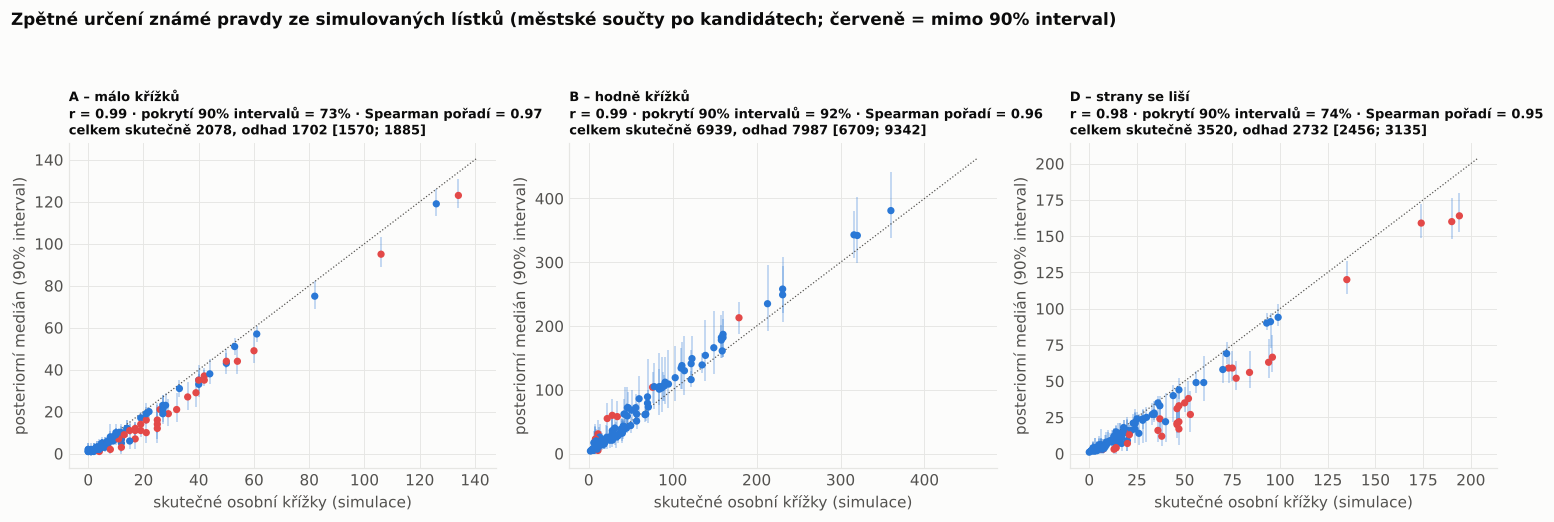

In [10]:
rec_results = []
for scen in ["A_malo_krizku", "B_hodne_krizku", "D_ruzne_strany"]:
    fn = FITS / f"recovery_{scen}.nc"
    if USE_CACHE and fn.exists() and (RES / f"recovery_{scen}.csv").exists():
        idata = az.from_netcdf(fn); tr = np.load(FITS / f"recovery_{scen}_truth.npz")
        summ = pd.read_csv(RES / f"recovery_{scen}.csv").iloc[0].to_dict()
        C_real = PO.realized_C(idata, tr["H"], D.rigorous_lower_bound(tr["H"]), seed=11)
        Cc = C_real.sum(axis=1); lo, hi = np.quantile(Cc, [0.05, 0.95], axis=0)
        rec_results.append(dict(name=scen, C_true=tr["C"].sum(0).ravel(), C_med=np.median(Cc, 0).ravel(), C_lo=lo.ravel(), C_hi=hi.ravel(), summary=summ))
        print(f"[cache] recovery {scen}")
    else:
        r = A.recovery_test(scen, cfg, seed=11, **REC_KW)
        r["idata"].to_netcdf(fn); pd.DataFrame([r["summary"]]).to_csv(RES / f"recovery_{scen}.csv", index=False)
        t = r["truth"]; np.savez(FITS / f"recovery_{scen}_truth.npz", C=t.C, S=t.S, H=t.H, N=t.N, pure=t.pure_marks)
        rec_results.append(r); print(f"[fit] recovery {scen}: {r['summary']['runtime_s']:.0f} s")
rec_tab = pd.DataFrame([r["summary"] for r in rec_results]).set_index("scenario")
cols = ["total_true", "total_med", "total_lo", "total_hi", "R_true", "R_med", "B_true", "B_med", "p_k0_true_mean", "p_k0_med_mean",
        "beta_true", "beta_med", "sigma_u_true", "sigma_u_med", "mbar_true", "mbar_med", "corr", "coverage90", "coverage50", "mae", "bias", "u_corr", "rank_corr", "top15_recovered_in_top20", "divergences", "max_rhat"]
display(rec_tab[cols].T)
fig = PL.fig_recovery(rec_results); plt.show()

**Čtení výsledků simulace.** Co model umí a co ne, je vidět přímo v tabulce a grafu: (i) pořadí kandidátů podle osobních křížků a relativní osobní efekty $u$ se obnovují dobře (korelace odhadů s pravdou, špička žebříčku zachována); (ii) $P(K=0)$ a $\beta$ se obnovují řádově správně; (iii) **celkový počet křížků se obnovuje jen přibližně** – ve scénářích s mnoha křížky od voličů bez strany je typicky podhodnocen (jejich rovnoměrně rozprostřené křížky model zčásti přičte stranickým lístkům – neidentifikovatelný směr), a 90% intervaly celkového součtu mohou být užší, než by měly být. Posteriorní součty proto interpretujeme jako **odhad identifikovatelné části osobních křížků** s dokazatelnou spodní mezí (LP) – ne jako přesné číslo. Pokrytí intervalů po kandidátech (sloupce `coverage90`, `coverage50`) ukazuje, kolik na intervalech můžeme stavět.

## 7. Fit hlavního modelu a MCMC diagnostika

NUTS (PyMC), 4 řetězce, `target_accept = 0.9`. Realizované počty křížků získáme z posterioru podmíněně na pozorovaném $H$: v modelu $H=S+C$ se složkami s rozptyly $\mathrm{Var}(S)=Bq(1-q)$ a $\mathrm{Var}(C)=\mu^C$, takže $C\mid H$ je (normální aproximace) posun o část rezidua; zaokrouhlíme a ořízneme na $[\text{rigorózní minimum},H]$ – dokazatelnou informaci, kterou nezávislá aproximace jinak ztrácí.

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [eta0, sigma_eta, z_eta, mbar_frac, r_split, g, sigma_a, sigma_e, z_a, z_e, beta, sigma_psi, z_psi, sigma_u, z_u, sigma_v, z_v, phi]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 527 seconds.


There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


[fit] main: 544 s


,0
n_chains,4.00
n_draws,"1,000.00"
divergences,1.00
max_rhat,1.01
min_ess_bulk,412.61
min_ess_tail,643.04
share_rhat_gt_1_01,0.00
share_ess_lt_400,0.00
sampling_time_s,526.93
max_treedepth_hits,0.00


                  mean        sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
beta             0.632     0.079     0.51     0.76      974     1587  1.00    0.0025   0.0013
sigma_u           0.42     0.064     0.33     0.53      662     1084  1.00    0.0025   0.0015
sigma_v          0.097     0.052    0.015     0.18      412      643  1.01    0.0026   0.0011
sigma_eta        0.205     0.163    0.017     0.51     1505     2004  1.00    0.0042   0.0032
sigma_psi        0.053     0.042   0.0044     0.13     1427     1790  1.00    0.0011  0.00099
sigma_a          0.389      0.18     0.15      0.7     1215     1408  1.01    0.0049   0.0036
sigma_e          0.189     0.069    0.075      0.3      762      658  1.00    0.0025   0.0017
phi               0.01    0.0073    0.001    0.024     2402     2506  1.00   0.00014  0.00011
mbar             12.19      0.58       11       13      569     1038  1.00     0.024    0.041
total_C_city  6.86e+03  8.01e+02     5600     8100      549 

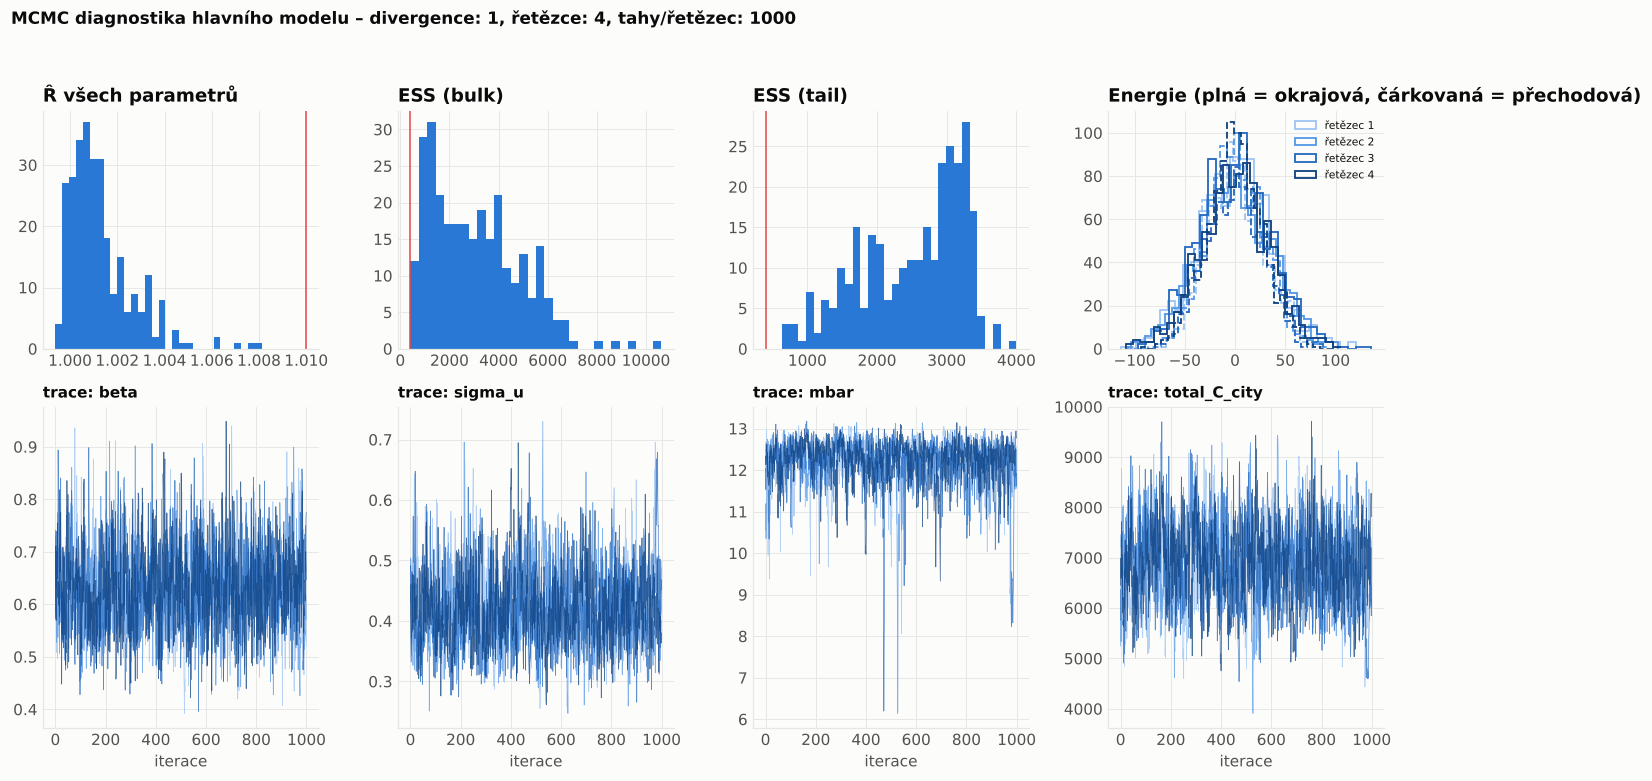

In [11]:
idata = fit_or_load("main", lambda: M.build_model(H, cfg), **MAIN_KW)
diag = PO.mcmc_diagnostics(idata)
summ_all = az.summary(idata, var_names=["eta0", "sigma_eta", "mbar", "r_split", "g", "sigma_a", "sigma_e", "a", "e", "beta", "sigma_psi", "theta", "sigma_u", "u", "sigma_v", "phi", "p_k0", "EK", "B", "R", "total_C_city"])
summ_all.to_csv(RES / "mcmc_summary_main.csv")
diag.to_csv(RES / "mcmc_diagnostics_main.csv", index=False)
display(diag.T)
print(summ_all.loc[["beta", "sigma_u", "sigma_v", "sigma_eta", "sigma_psi", "sigma_a", "sigma_e", "phi", "mbar", "total_C_city"]].to_string())
assert diag.iloc[0]["max_rhat"] < 1.05, "R-hat > 1.05 – zkontroluj konvergenci"
fig = PL.fig_mcmc(idata, summ_all); plt.show()

### 7.1 Posterior predictive checks
Replikujeme $H$ z posterioru (mechanistický rozptyl) a porovnáme s pozorováním po pořadí, stranách, okrscích a po všech 32 blocích; rezidua standardizujeme.

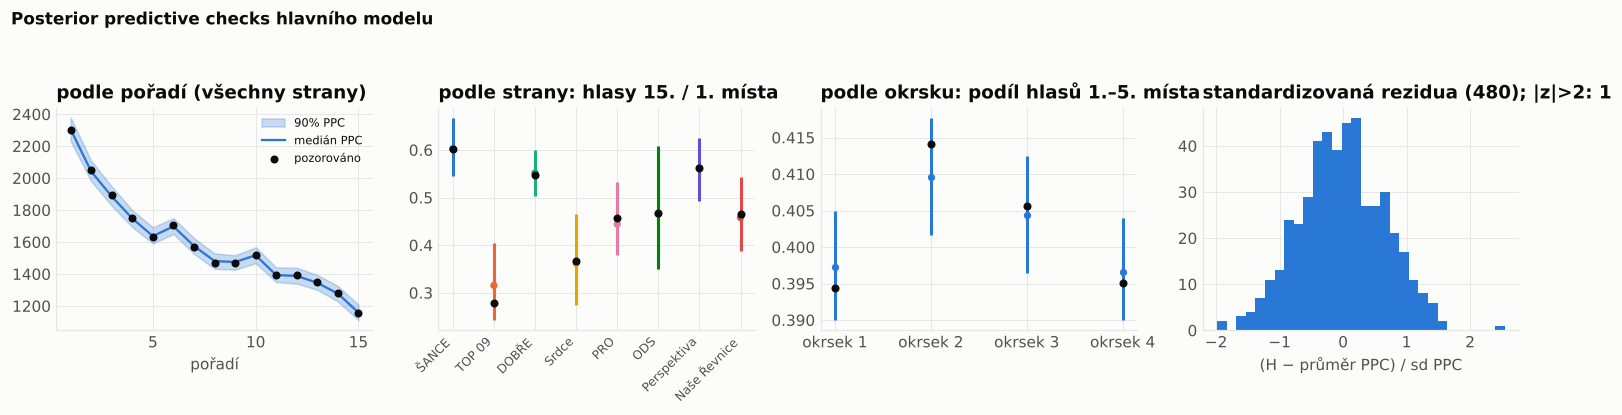

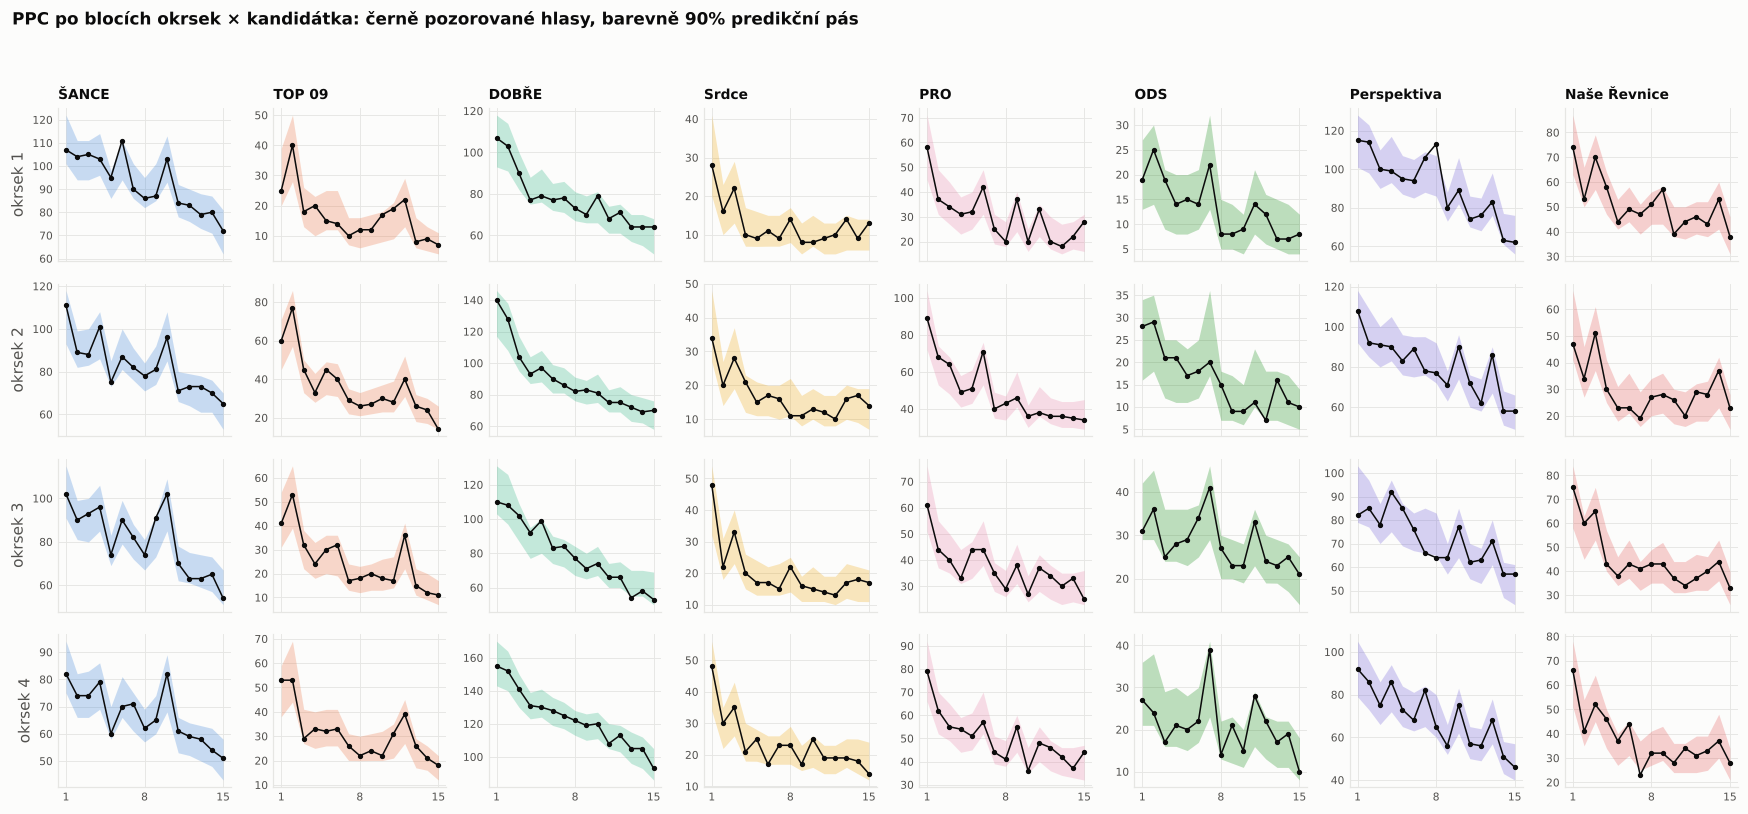

Standardizovaná rezidua: sd = 0.67, |z| > 2: 1 z 480 (očekáváno ~22 při kalibraci), |z| > 3: 0


,okrsek,strana,pozice,kandidát,H,ppc_mean,ppc_sd,z
97,1,7,8,Kovářová Iveta,113,96.45,6.50,2.55
471,4,8,7,Grund Jiří MSc.,23,30.36,3.70,-1.99
282,3,3,13,Radová Jitka,54,62.78,4.70,-1.87
337,3,7,8,Kovářová Iveta,64,73.25,5.57,-1.66
336,3,7,7,Šebesta Karel Mgr.,66,75.56,5.84,-1.64
5,1,1,6,Soukupová Květa Ing.,111,101.86,5.60,1.63
248,3,1,9,Sudek Martin Ing.,91,81.81,5.75,1.60
206,2,6,12,Blechová Zuzana,7,12.39,3.50,-1.54


In [12]:
ppc = A.posterior_predictive(idata, H.shape, n=500, seed=SEED)
fig = PL.fig_ppc(d, ppc); plt.show()
fig = PL.fig_ppc_blocks(d, ppc); plt.show()
mu_rep, sd_rep = ppc.mean(0), ppc.std(0) + 1e-9
z = (H - mu_rep) / sd_rep
ppc_tab = pd.DataFrame({"okrsek": np.repeat(np.arange(1, 5), 120), "strana": np.tile(np.repeat(np.arange(1, 9), 15), 4), "pozice": np.tile(np.arange(1, 16), 32), "H": H.ravel(), "ppc_mean": mu_rep.ravel(), "ppc_sd": sd_rep.ravel(), "z": z.ravel()})
ppc_tab.to_csv(RES / "ppc_residuals.csv", index=False, sep=";", encoding="utf-8-sig")
print(f"Standardizovaná rezidua: sd = {z.std():.2f}, |z| > 2: {(np.abs(z) > 2).sum()} z 480 (očekáváno ~{0.046*480:.0f} při kalibraci), |z| > 3: {(np.abs(z) > 3).sum()}")
worst = ppc_tab.reindex(ppc_tab.z.abs().sort_values(ascending=False).index).head(8).copy()
worst["kandidát"] = [d.names[s - 1, i - 1] for s, i in zip(worst.strana, worst.pozice)]
display(worst[["okrsek", "strana", "pozice", "kandidát", "H", "ppc_mean", "ppc_sd", "z"]])

## 8. Výsledky

### 8.1 Celkový obraz: stranické lístky, křížky, rozdělení K


| veličina (město) | medián | 90% interval | typ |
|---|---:|---:|---|
| individuální křížky celkem | **6 878** (28,7 % hlasů) | 5 621 – 8 202 | modelový odhad (podmíněný priory; v simulacích chyba součtu -22 % až +15 %) |
| rigorózní dolní mez (LP) | **2 890** (12,1 %) | – | dokazatelná mez |
| lístky s označenou stranou (k ≤ 14) | 1 217 | 1 105 – 1 347 | modelový odhad |
| lístky bez strany | 462 (27,5 % lístků) | 332 – 574 | modelový odhad, slabě identifikováno |
| průměr křížků na lístku bez strany m̄ | 12,3 | 11,2 – 12,8 | modelový odhad, slabě identifikováno |
| křížky z lístků bez strany R | 5 685 | 3 736 – 7 369 | modelový odhad |
| průměrné E[K] (vážené) – křížky jinde na lístku se stranou | 0,97 | 0,61 – 1,53 | modelový odhad |


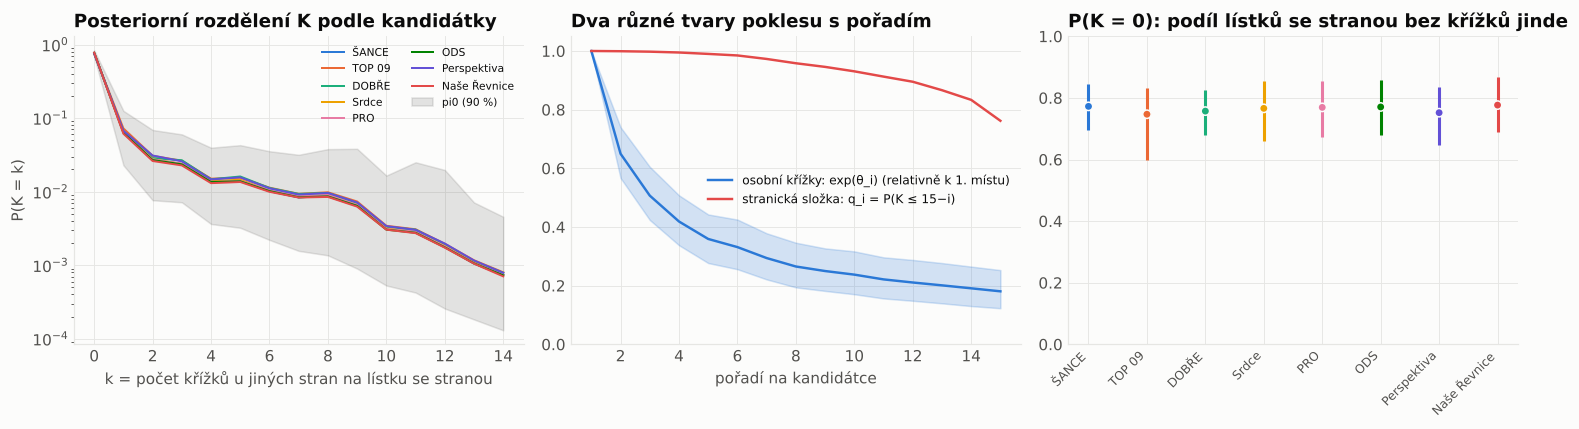

In [13]:
post = idata.posterior
rec_bias = rec_tab["total_med"] / rec_tab["total_true"] - 1
rec_bias_min, rec_bias_max = float(rec_bias.min()), float(rec_bias.max())
C_real = PO.realized_C(idata, H, lb_prec, seed=SEED)           # (n, 4, 8, 15) realizované křížky
tot = C_real.sum(axis=(1, 2, 3))
q = lambda x, p=(0.05, 0.5, 0.95): np.quantile(x, p)
tq, Rq, Mq, mbq, Bq = q(tot), q(PO.stack_draws(post["R"]).sum(1)), q(PO.stack_draws(post["M_city"])), q(PO.stack_draws(post["mbar"])), q(PO.stack_draws(post["B_city"]))
EKw = (PO.stack_draws(post["EK"]) * PO.stack_draws(post["B"]).sum(1)).sum(1) / PO.stack_draws(post["B"]).sum((1, 2))
display(Markdown(czfmt(f'''
| veličina (město) | medián | 90% interval | typ |
|---|---:|---:|---|
| individuální křížky celkem | **{tq[1]:,.0f}** ({tq[1]/23939:.1%} hlasů) | {tq[0]:,.0f} – {tq[2]:,.0f} | modelový odhad (podmíněný priory; v simulacích chyba součtu {rec_bias_min:+.0%} až {rec_bias_max:+.0%}) |
| rigorózní dolní mez (LP) | **{LB_LP:,}** ({LB_LP/23939:.1%}) | – | dokazatelná mez |
| lístky s označenou stranou (k ≤ 14) | {Bq[1]:,.0f} | {Bq[0]:,.0f} – {Bq[2]:,.0f} | modelový odhad |
| lístky bez strany | {Mq[1]:,.0f} ({Mq[1]/V_CITY:.1%} lístků) | {Mq[0]:,.0f} – {Mq[2]:,.0f} | modelový odhad, slabě identifikováno |
| průměr křížků na lístku bez strany m̄ | {mbq[1]:.1f} | {mbq[0]:.1f} – {mbq[2]:.1f} | modelový odhad, slabě identifikováno |
| křížky z lístků bez strany R | {Rq[1]:,.0f} | {Rq[0]:,.0f} – {Rq[2]:,.0f} | modelový odhad |
| průměrné E[K] (vážené) – křížky jinde na lístku se stranou | {np.median(EKw):.2f} | {np.quantile(EKw, .05):.2f} – {np.quantile(EKw, .95):.2f} | modelový odhad |
''')))
fig = PL.fig_k_and_position(idata); plt.show()

### 8.2 Kandidáti: posteriorní žebříček osobních křížků, osobní efekt a robustnost pořadí

Tabulka obsahuje pro všech 120 kandidátů: hlasy (město i okrsky), rigorózní minimum, posteriorní medián realizovaných křížků, 50% / 90% / 95% intervaly, očekávanou intenzitu $\mu^C$, osobní efekt $u$ (log-škála, po očištění o pozici, stranu a okrsek; $P(u>0)$), posteriorní pořadí podle křížků a jeho 90% interval, a srovnání s předchozím scénářovým modelem (pouze benchmark).

,party,position,name,elected,votes_city,lb_precinct_sum,C_median,C_q25,C_q75,C_q05,C_q95,C_share_median,u_median,p_u_positive,rank_median,rank_q05,rank_q95,robust_rank,baseline_median
0,DOBŘE,1,Štěpánková Martina Mgr. MPA,True,512,0,183.00,171.00,196.00,152.00,214.00,0.36,0.26,0.91,1.00,1.00,3.00,stabilní,197.30
1,PRO,1,Kvasnička Libor,True,287,0,174.00,167.00,181.00,157.00,192.00,0.61,0.17,0.83,2.00,1.00,4.00,stabilní,167.80
2,TOP 09,2,Hartmann Pavel Ing.,True,223,44,168.00,161.00,174.00,152.00,184.00,0.75,0.62,1.00,3.00,1.00,5.00,stabilní,169.70
3,DOBŘE,2,Uhlík Michal Ing. Ph.D.,True,491,0,163.00,150.00,175.00,132.00,193.00,0.33,0.52,1.00,4.00,2.00,6.00,stabilní,176.40
4,Naše Řevnice,1,Kozák Petr Ing.,True,262,0,153.00,147.00,161.00,137.00,171.05,0.58,-0.01,0.47,5.00,3.00,7.00,stabilní,146.60
5,Perspektiva,1,Smrčka Tomáš Ing.,True,397,0,149.00,134.00,164.00,109.00,186.00,0.38,-0.31,0.06,6.00,2.00,10.00,stabilní,134.50
6,Naše Řevnice,3,Sedláčková Davidová Markéta,True,238,50,130.00,123.00,137.00,114.00,148.00,0.55,0.43,0.99,8.00,6.00,12.00,stabilní,122.60
7,Perspektiva,2,Hartmann Petr Ing.,True,377,3,129.00,114.00,144.00,89.95,166.00,0.34,-0.07,0.35,8.00,6.00,15.00,stabilní,114.50
8,TOP 09,1,Tlustý Josef Ing. arch.,False,179,0,123.00,117.00,130.00,108.00,140.00,0.69,-0.11,0.28,10.00,7.00,15.00,stabilní,125.70
9,Perspektiva,4,Hrubý Vratislav,True,367,25,121.00,107.00,135.00,84.00,157.00,0.33,0.28,0.95,11.00,7.00,18.00,stabilní,105.00


Upozornění: v simulacích (odd. 6) pokryly nominálně 90% intervaly skutečnou hodnotu u 73%–92% kandidátů; intervaly níže proto čtěte jako orientační (spíše ~80% než 90%). Pořadí kandidátů bylo v simulacích robustní (Spearman 0.95–0.97).


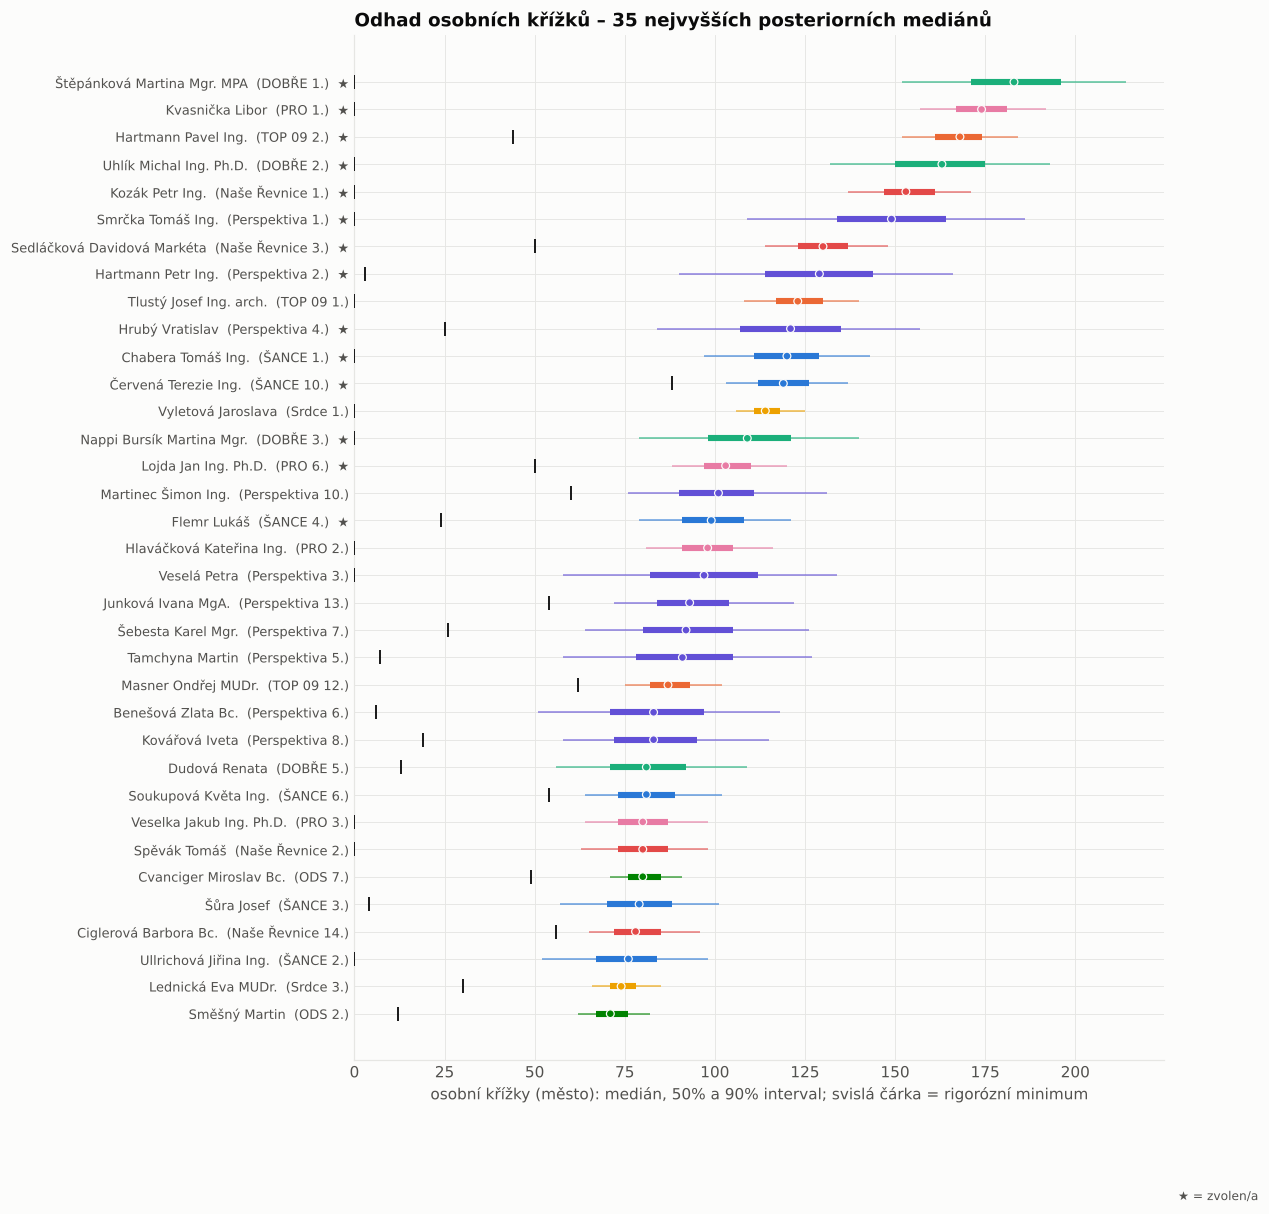

In [14]:
base = pd.read_csv(ROOT / "context" / "predchozi_scenarovy_model_POUZE_BASELINE" / "revnice_model_osobnich_krizku_120.csv", sep=";", encoding="utf-8-sig")
short2pid = {v: k for k, v in D.PARTY_SHORT.items()}
base["party_id"] = base["strana"].map(short2pid); base["position"] = base["poradi_na_kandidatce"].astype(int)
base_df = base[["party_id", "position", "model_median_krizku", "model_rozpeti_10pct", "model_rozpeti_90pct", "nad_ocekavani_median"]].rename(
    columns={"model_median_krizku": "baseline_median", "model_rozpeti_10pct": "baseline_p10", "model_rozpeti_90pct": "baseline_p90", "nad_ocekavani_median": "baseline_excess"})
tab = PO.candidate_table(idata, d, C_real, baseline_df=base_df)
tab["C_minus_lb"] = tab["C_median"] - tab["lb_precinct_sum"]
tab["robust_rank"] = np.where(tab["rank_width_90"] <= 15, "stabilní", np.where(tab["rank_width_90"] <= 40, "střední", "nestabilní"))
tab.to_csv(RES / "candidate_estimates.csv", index=False, sep=";", encoding="utf-8-sig")
show = ["party", "position", "name", "elected", "votes_city", "lb_precinct_sum", "C_median", "C_q25", "C_q75", "C_q05", "C_q95", "C_share_median", "u_median", "p_u_positive", "rank_median", "rank_q05", "rank_q95", "robust_rank", "baseline_median"]
display(tab.sort_values("C_median", ascending=False)[show].head(30).reset_index(drop=True))
print(f"Upozornění: v simulacích (odd. 6) pokryly nominálně 90% intervaly skutečnou hodnotu u {rec_tab.coverage90.min():.0%}–{rec_tab.coverage90.max():.0%} kandidátů; "
      f"intervaly níže proto čtěte jako orientační (spíše ~80% než 90%). Pořadí kandidátů bylo v simulacích robustní (Spearman {rec_tab.rank_corr.min():.2f}–{rec_tab.rank_corr.max():.2f}).")
fig = PL.fig_posterior_ranking(tab); plt.show()

Nejsilnější osobní efekt (u):


,party,position,name,elected,votes_city,lb_precinct_sum,C_median,C_q05,C_q95,u_median,u_q05,u_q95,p_u_positive
0,ŠANCE,10,Červená Terezie Ing.,True,383,88,119.00,103.00,137.00,1.12,0.78,1.54,1.00
1,TOP 09,12,Masner Ondřej MUDr.,False,137,62,87.00,75.00,102.00,0.96,0.64,1.33,1.00
2,ODS,7,Cvanciger Miroslav Bc.,False,122,49,80.00,71.00,91.00,0.83,0.54,1.16,1.00
3,Naše Řevnice,14,Ciglerová Barbora Bc.,False,171,56,78.00,65.00,96.00,0.80,0.48,1.16,1.00
4,Perspektiva,13,Junková Ivana MgA.,False,308,54,93.00,72.00,122.00,0.68,0.35,1.11,1.00
5,PRO,6,Lojda Jan Ing. Ph.D.,True,214,50,103.00,88.00,120.00,0.64,0.35,0.96,1.00
6,TOP 09,2,Hartmann Pavel Ing.,True,223,44,168.00,152.00,184.00,0.62,0.32,0.94,1.00
7,Perspektiva,10,Martinec Šimon Ing.,False,331,60,101.00,76.00,131.00,0.61,0.30,0.99,1.00
8,ODS,11,Černý Miroslav,False,86,32,46.00,38.00,57.00,0.55,0.23,0.91,1.00
9,DOBŘE,2,Uhlík Michal Ing. Ph.D.,True,491,0,163.00,132.00,193.00,0.52,0.22,0.86,1.00


Nejslabší osobní efekt (u) – kandidáti, kteří dostávají méně křížků, než odpovídá pozici:


,party,position,name,elected,votes_city,lb_precinct_sum,C_median,C_q05,C_q95,u_median,u_q05,u_q95,p_u_positive
0,PRO,10,Krofta Matěj,False,119,0,16.00,6.00,31.00,-0.67,-1.21,-0.24,0.00
1,ŠANCE,5,Foldynová Renáta,False,304,0,26.00,10.00,47.00,-0.61,-1.16,-0.21,0.00
2,TOP 09,15,Brodský Tomáš,False,50,0,12.00,4.00,23.00,-0.58,-1.13,-0.13,0.02
3,ODS,1,Schlindenbuch Anna Mgr.,False,105,0,62.00,52.00,73.00,-0.53,-0.88,-0.19,0.01
4,Naše Řevnice,7,Grund Jiří MSc.,False,130,6,25.00,14.00,42.00,-0.51,-0.94,-0.14,0.01
5,Srdce,9,Svobodová Ivanka,False,52,1,11.00,5.00,21.00,-0.50,-1.03,-0.07,0.03
6,Naše Řevnice,5,Doubek Gabriela,False,142,0,35.00,21.00,53.00,-0.48,-0.86,-0.13,0.01
7,DOBŘE,13,Radová Jitka,False,295,0,17.00,6.00,34.00,-0.47,-1.03,0.03,0.06


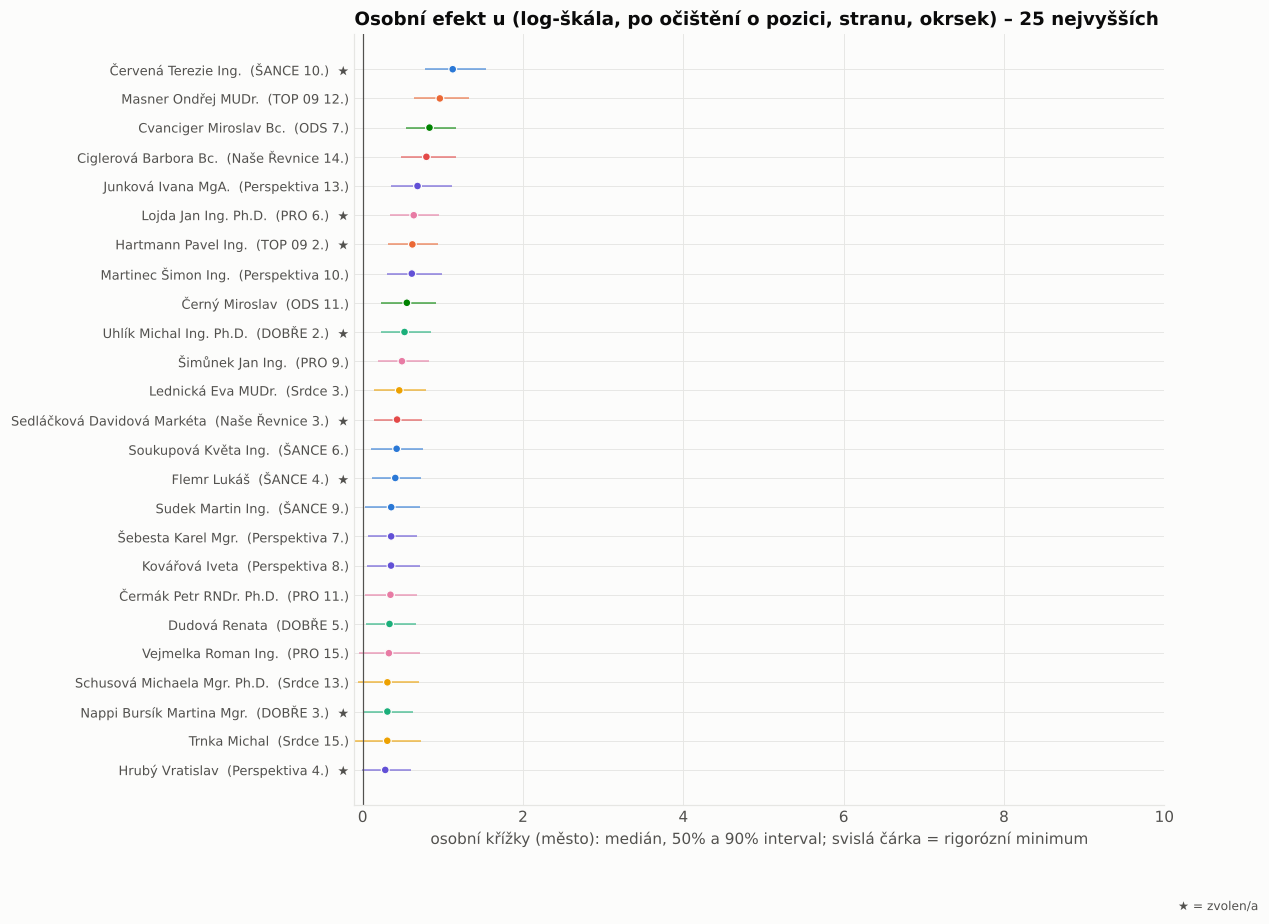

In [15]:
# Osobnosti: kandidáti s nejvyšším osobním efektem u (po očištění o pozici) – tedy ti, kdo dostávají víc křížků,
# než by odpovídalo jejich pozici, straně a okrsku
show_u = ["party", "position", "name", "elected", "votes_city", "lb_precinct_sum", "C_median", "C_q05", "C_q95", "u_median", "u_q05", "u_q95", "p_u_positive"]
print("Nejsilnější osobní efekt (u):"); display(tab.sort_values("u_median", ascending=False)[show_u].head(15).reset_index(drop=True))
print("Nejslabší osobní efekt (u) – kandidáti, kteří dostávají méně křížků, než odpovídá pozici:"); display(tab.sort_values("u_median")[show_u].head(8).reset_index(drop=True))
fig = PL.fig_posterior_ranking(tab.assign(C_median=tab.u_median, C_q05=tab.u_q05, C_q95=tab.u_q95, C_q25=tab.u_median, C_q75=tab.u_median, lb_precinct_sum=np.nan), n=25,
                                 name="fig04b_osobni_efekt_u.png", title="Osobní efekt u (log-škála, po očištění o pozici, stranu, okrsek) – 25 nejvyšších"); plt.show()

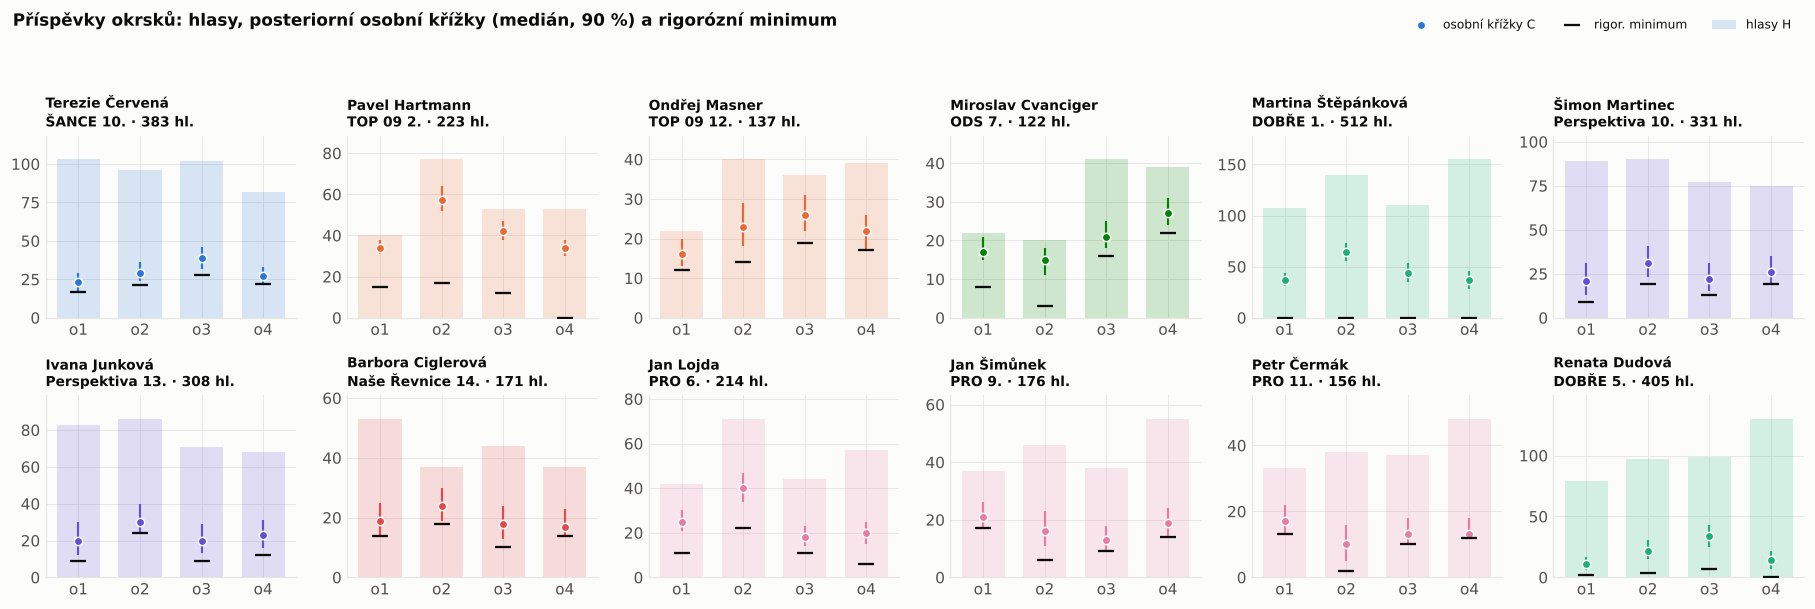


**Terezie Červená** (ŠANCE, 10. místo, zvolena): hlasy 383 = 103+96+102+82.
Rigorózní minimum 88 (po okrscích [17, 21, 28, 22]). Modelový odhad osobních křížků: **119** (50 %: 112–126; 90 %: 103–137), tj. 31 % jejích hlasů;
po okrscích mediány 23 [17; 29], 29 [24; 36], 39 [32; 46], 27 [22; 33]. Osobní efekt u = +1,12 [+0,78; +1,54], P(u>0) = 1,00; posteriorní pořadí podle křížků 11 (7–18).
Předchozí scénářový model: medián 126 (10.–90. percentil scénářů 107–158) – jiná metoda, nejde o interval spolehlivosti.


In [16]:
# Terezie Červená (ŠANCE, 10. místo) a další vybraní kandidáti po okrscích
sel = [(1, 10), (2, 2), (2, 12), (6, 7), (3, 1), (7, 10), (7, 13), (8, 14), (5, 6), (5, 9), (5, 11), (3, 5)]
fig = PL.fig_precinct_contributions(d, C_real, sel); plt.show()
cz = tab[tab.name.str.contains("Červená")].iloc[0]
per_p = np.median(C_real[:, :, 0, 9], axis=0); lo_p, hi_p = np.quantile(C_real[:, :, 0, 9], [0.05, 0.95], axis=0)
display(Markdown(czfmt(f'''
**Terezie Červená** (ŠANCE, 10. místo, zvolena): hlasy {cz.votes_city} = {cz.votes_p1}+{cz.votes_p2}+{cz.votes_p3}+{cz.votes_p4}.
Rigorózní minimum {cz.lb_precinct_sum} (po okrscích {lb_prec[:, 0, 9].tolist()}). Modelový odhad osobních křížků: **{cz.C_median:.0f}** (50 %: {cz.C_q25:.0f}–{cz.C_q75:.0f}; 90 %: {cz.C_q05:.0f}–{cz.C_q95:.0f}), tj. {cz.C_share_median:.0%} jejích hlasů;
po okrscích mediány {", ".join(f"{m:.0f} [{l:.0f}; {h:.0f}]" for m, l, h in zip(per_p, lo_p, hi_p))}. Osobní efekt u = {cz.u_median:+.2f} [{cz.u_q05:+.2f}; {cz.u_q95:+.2f}], P(u>0) = {cz.p_u_positive:.2f}; posteriorní pořadí podle křížků {cz.rank_median:.0f} ({cz.rank_q05:.0f}–{cz.rank_q95:.0f}).
Předchozí scénářový model: medián {cz.baseline_median:.0f} (10.–90. percentil scénářů {cz.baseline_p10:.0f}–{cz.baseline_p90:.0f}) – jiná metoda, nejde o interval spolehlivosti.
''')))

### 8.3 Rozklad hlasů na stranickou a osobní složku – příklady kandidátek

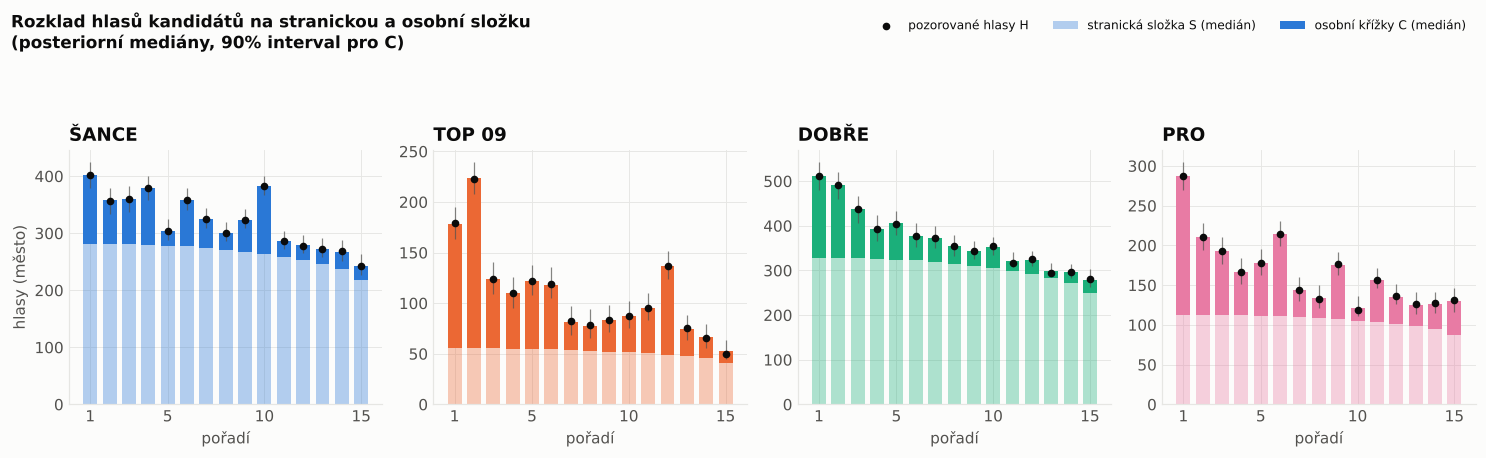

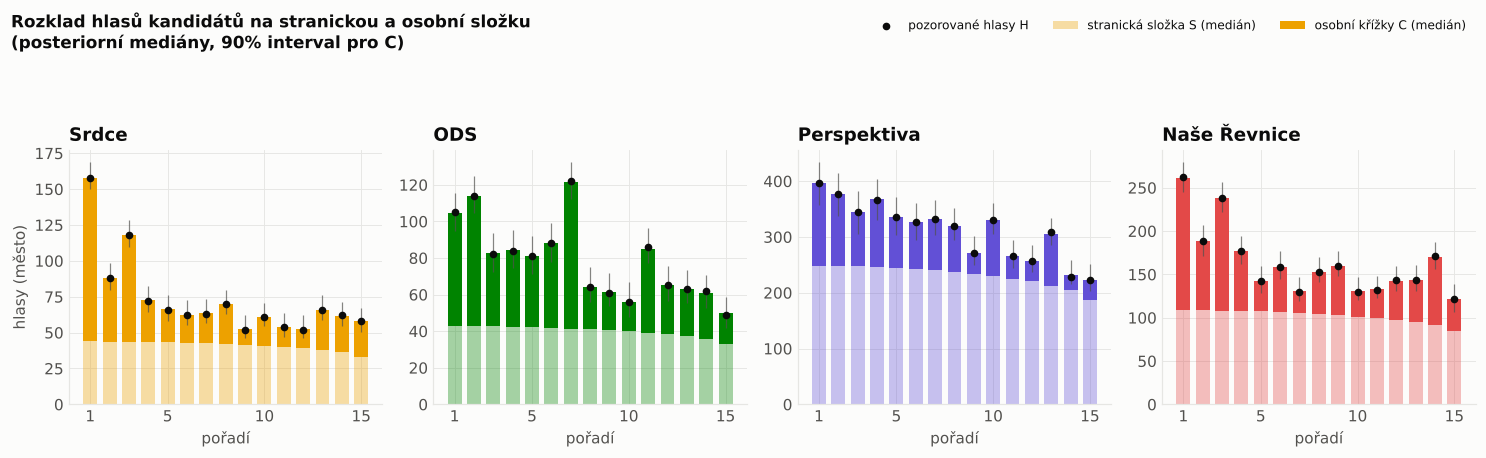

In [17]:
S_draws = PO.stack_draws(post["S"]).sum(axis=1)   # (n, 8, 15) město
C_city = C_real.sum(axis=1)
S_med, C_med = np.median(S_draws, 0), np.median(C_city, 0)
C_lo, C_hi = np.quantile(C_city, [0.05, 0.95], axis=0)
fig = PL.fig_decomposition(d, S_med, C_med, C_lo, C_hi, parties=(1, 2, 3, 5)); plt.show()
fig = PL.fig_decomposition(d, S_med, C_med, C_lo, C_hi, parties=(4, 6, 7, 8), save=False); fig.savefig(FIG / "fig05b_rozklad_strana_vs_individual_2.png"); plt.show()

### 8.4 Kandidátky a okrsky

In [18]:
party_tab = PO.party_table(idata, d, C_real)
party_tab["C_share_lb_lp_note"] = "LP mez platí jen pro součty okrsků, ne pro strany"
party_tab.to_csv(RES / "party_estimates.csv", index=False, sep=";", encoding="utf-8-sig")
display(party_tab[["party", "votes", "lb_precinct_sum", "C_median", "C_q05", "C_q95", "C_share_median", "C_share_q05", "C_share_q95", "B_total_median", "p_k0_median", "p_k0_q05", "p_k0_q95", "EK_median"]])
prec_tab = PO.precinct_table(idata, d, C_real, [r["min_total_C"] for r in lp])
prec_tab.to_csv(RES / "precinct_estimates.csv", index=False, sep=";", encoding="utf-8-sig")
display(prec_tab[["precinct", "votes", "max_party_ballots", "lb_monotone", "lb_lp", "C_median", "C_q05", "C_q95", "C_share_median", "party_ballots_median", "pure_marks_median", "marks_from_party_voters_median"]])
# kontrola konzistence: posteriorní realizované C >= LP mez v každém okrsku?
Cp = C_real.sum(axis=(2, 3))
print("Podíl posteriorních tahů, kde celkové C v okrsku ≥ LP mez:", [f"{(Cp[:, p] >= lp[p]['min_total_C']).mean():.2f}" for p in range(4)])

,party,votes,lb_precinct_sum,C_median,C_q05,C_q95,C_share_median,C_share_q05,C_share_q95,B_total_median,p_k0_median,p_k0_q05,p_k0_q95,EK_median
0,ŠANCE,4840,238,871.00,662.00,"1,145.00",0.18,0.14,0.24,281.72,0.77,0.70,0.84,0.92
1,TOP 09,1630,200,857.00,681.00,"1,076.00",0.53,0.42,0.66,55.51,0.75,0.60,0.83,1.02
2,DOBŘE,5553,42,954.00,684.95,"1,306.05",0.17,0.12,0.24,328.71,0.76,0.68,0.83,1.00
3,Srdce,1102,128,488.00,392.00,631.00,0.44,0.36,0.57,43.84,0.77,0.66,0.85,0.94
4,PRO,2498,207,912.00,731.00,"1,146.05",0.37,0.29,0.46,112.86,0.77,0.67,0.86,0.94
5,ODS,1182,174,579.00,456.00,731.05,0.49,0.39,0.62,42.75,0.77,0.68,0.86,0.92
6,Perspektiva,4683,205,"1,213.50",847.00,"1,691.05",0.26,0.18,0.36,248.19,0.75,0.65,0.84,1.01
7,Naše Řevnice,2451,299,922.00,740.00,"1,175.00",0.38,0.30,0.48,108.60,0.78,0.69,0.87,0.90


,precinct,votes,max_party_ballots,lb_monotone,lb_lp,C_median,C_q05,C_q95,C_share_median,party_ballots_median,pure_marks_median,marks_from_party_voters_median
0,1,5778,385.20,343,646.00,"1,541.00","1,233.95","1,884.00",0.27,302.31,"1,243.41",290.85
1,2,6012,400.80,352,776.00,"1,946.00","1,569.00","2,338.00",0.32,289.58,"1,668.26",280.77
2,3,5818,387.87,377,708.00,"1,747.00","1,407.95","2,122.00",0.30,290.27,"1,464.02",279.58
3,4,6331,422.07,421,761.00,"1,621.00","1,321.00","1,961.05",0.26,335.82,"1,293.67",326.00


Podíl posteriorních tahů, kde celkové C v okrsku ≥ LP mez: ['1.00', '1.00', '1.00', '1.00']


### 8.5 Přidávají okrsková data něco oproti městským součtům?

Tři pohledy: (i) rigorózní meze (1 096 → 1 493 monotónní; LP viz tabulka v odd. 3 → LP po okrscích); (ii) sdílený osobní efekt $u_{s,i}$ vyžaduje konzistenci napříč 4 okrsky – kandidát s převisem jen v jednom okrsku dostane menší $u$ než kandidát s převisem všude; (iii) **leave-one-precinct-out**: model natrénovaný na 3 okrscích predikuje rozdělení hlasů 120 kandidátů ve čtvrtém (při známých součtech stran v něm). Srovnáváme model s osobními efekty, bez nich, naivní prediktor „podíly kandidátů v ostatních okrscích“ a rovnoměrný prediktor. **n = 4 – jde o ilustraci, ne o test s výpovědní silou.**

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [eta0, sigma_eta, z_eta, mbar_frac, r_split, g, sigma_a, sigma_e, z_a, z_e, beta, sigma_psi, z_psi, sigma_u, z_u, sigma_v, z_v, phi]


Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 144 seconds.


There were 4 divergences after tuning. Increase `target_accept` or reparameterize.


...

The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


[fit] LOPO: 846 s


,precinct_out,mae_model s u,lpd_model s u,mae_model bez u,lpd_model bez u,mae_naivní podíly,lpd_naivní podíly,mae_rovnoměrně,lpd_rovnoměrně,divergences
0,1,3.91,-378.47,5.04,-391.85,3.89,-388.49,8.15,-447.64,4
1,2,3.95,-387.18,4.90,-395.88,4.18,-397.63,9.84,-469.58,0
2,3,4.22,-391.17,6.00,-407.33,4.02,-396.98,9.31,-463.46,0
3,4,4.39,-395.99,4.89,-405.77,4.27,-402.56,8.55,-459.19,24


Průměr přes 4 okrsky:


,mae_model s u,lpd_model s u,mae_model bez u,lpd_model bez u,mae_naivní podíly,lpd_naivní podíly,mae_rovnoměrně,lpd_rovnoměrně
průměr,4.11,-388.20,5.21,-400.21,4.09,-396.42,8.96,-459.97


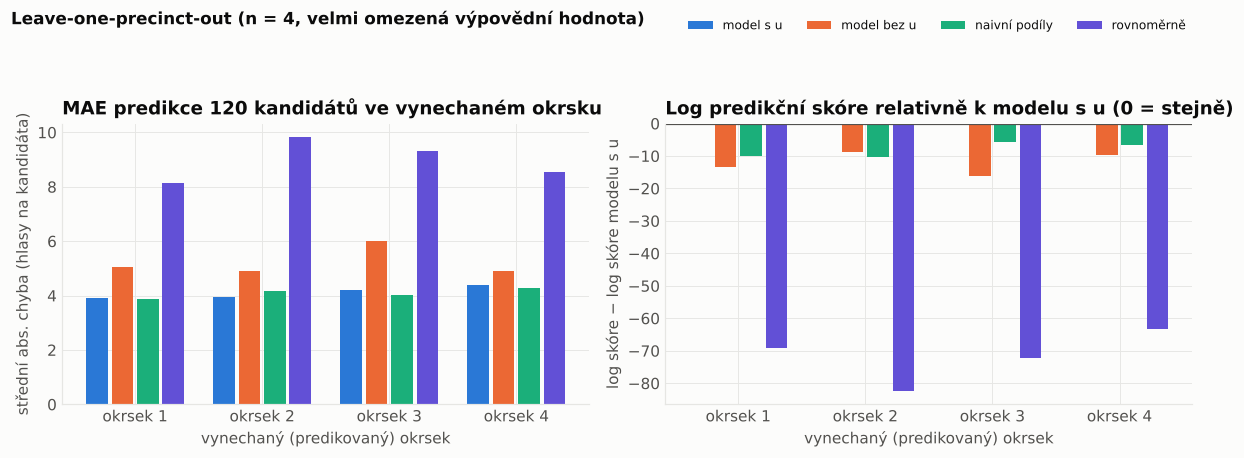

In [19]:
fn = RES / "lopo.csv"
if USE_CACHE and fn.exists():
    lopo_tab = pd.read_csv(fn); print("[cache] lopo.csv")
else:
    t0 = time.time(); lopo_tab = A.lopo(H, cfg, seed=SEED, **SUB_KW); lopo_tab.to_csv(fn, index=False); print(f"[fit] LOPO: {time.time()-t0:.0f} s")
display(lopo_tab)
print("Průměr přes 4 okrsky:"); display(lopo_tab.drop(columns=["precinct_out", "divergences"]).mean().to_frame("průměr").T)
fig = PL.fig_lopo(lopo_tab); plt.show()

### 8.6 Citlivost na priory a likelihood

Každou variantu fitujeme znovu (kratší řetězce) a sledujeme celkový počet křížků, $P(K=0)$, $\bar m$, odhad pro Terezii Červenou a $\beta$. Varianty: prior $P(K=0)$ 0,3 / 0,7; ocas $K$ krátký / dlouhý; prior $\bar m$ rovnoměrný / vysoký; neinformativní prior sklonu pozice; úzký / široký prior $\sigma_u$; Poissonova likelihood; model bez saturace. Rozpětí mediánů napříč variantami je **scénářové rozpětí**, nikoli posteriorní interval.

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [eta0, sigma_eta, z_eta, mbar_frac, r_split, g, sigma_a, sigma_e, z_a, z_e, beta, sigma_psi, z_psi, sigma_u, z_u, sigma_v, z_v, phi]


Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 292 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


...

There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


[fit] citlivost: 3299 s


,label,total_C_median,total_C_q05,total_C_q95,share_C_median,p_k0_mean_median,mbar_median,cervena_C_median,cervena_C_q05,cervena_C_q95,beta_median,sigma_u_median,divergences,max_rhat
0,hlavní model,"6,882.50","5,621.00","8,188.50",0.29,0.76,12.30,119.00,103.00,137.00,0.63,0.41,1,1.01
1,"P(K=0) prior 0,30","6,674.00","5,316.55","8,018.10",0.28,0.75,12.15,117.00,101.00,137.00,0.63,0.42,0,1.02
2,"P(K=0) prior 0,70","6,957.50","5,724.95","8,363.25",0.29,0.77,12.37,119.00,104.00,138.00,0.63,0.41,0,1.02
3,"ocas K: ratio 0,50 (krátký)","7,729.00","6,690.85","9,044.30",0.32,0.80,12.78,123.00,109.00,142.05,0.63,0.38,0,1.02
4,"ocas K: ratio 0,85 (dlouhý)","5,564.00","4,601.95","7,040.25",0.23,0.70,10.48,111.00,96.00,130.00,0.63,0.50,0,1.02
5,m̄ prior rovnoměrný,"7,013.50","5,708.00","8,354.00",0.29,0.77,12.37,119.00,103.00,139.00,0.62,0.41,3,1.02
6,"m̄ prior vysoký (Beta 5,2)","6,923.00","5,739.75","8,310.05",0.29,0.76,12.33,119.00,103.00,138.00,0.63,0.41,0,1.02
7,"efekt pozice: prior β ~ N(0, 1)","6,903.00","5,520.95","8,305.15",0.29,0.76,12.31,119.00,102.00,137.00,0.62,0.41,0,1.02
8,"σ_u prior úzký (HN 0,25)","7,165.00","5,945.00","8,441.20",0.30,0.77,12.43,120.00,105.00,140.00,0.61,0.39,0,1.03
9,"σ_u prior široký (HN 1,5)","6,863.00","5,664.80","8,234.05",0.29,0.76,12.30,119.00,103.00,137.00,0.63,0.41,0,1.03


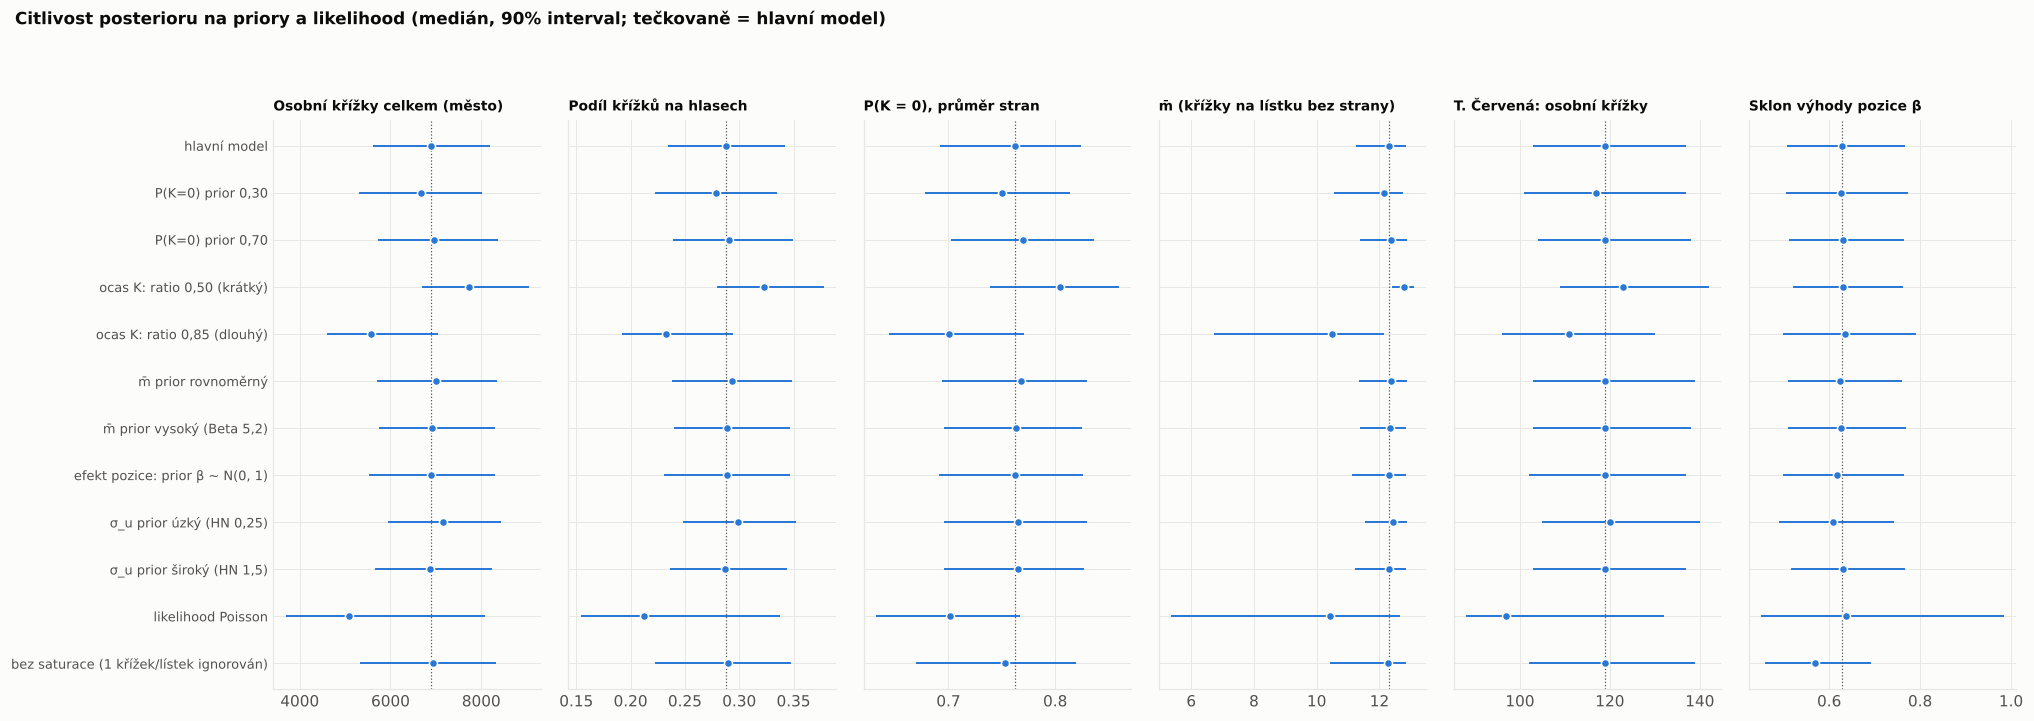

Scénářové rozpětí mediánů celkového počtu křížků napříč variantami: 5,075 – 7,729; sjednocení 90% intervalů: 3,687 – 9,044. Terezie Červená: mediány 97 – 123.


In [20]:
fn = RES / "sensitivity.csv"
if USE_CACHE and fn.exists():
    sens = pd.read_csv(fn); print("[cache] sensitivity.csv")
else:
    t0 = time.time(); sens, _ = A.run_sensitivity(H, cfg, seed=SEED, idata_main=idata, **SUB_KW); sens.to_csv(fn, index=False); print(f"[fit] citlivost: {time.time()-t0:.0f} s")
display(sens[["label", "total_C_median", "total_C_q05", "total_C_q95", "share_C_median", "p_k0_mean_median", "mbar_median", "cervena_C_median", "cervena_C_q05", "cervena_C_q95", "beta_median", "sigma_u_median", "divergences", "max_rhat"]])
fig = PL.fig_sensitivity(sens); plt.show()
print(f"Scénářové rozpětí mediánů celkového počtu křížků napříč variantami: {sens.total_C_median.min():,.0f} – {sens.total_C_median.max():,.0f}; "
      f"sjednocení 90% intervalů: {sens.total_C_q05.min():,.0f} – {sens.total_C_q95.max():,.0f}. Terezie Červená: mediány {sens.cervena_C_median.min():.0f} – {sens.cervena_C_median.max():.0f}.")

### 8.7 Srovnání s baseline modely

* **Model bez osobních efektů** (jen strana + pořadí + okrsek, $\sigma_u=\sigma_v=0$): srovnání predikční přesnosti přes PSIS-LOO (ArviZ). U hlavního modelu jsou pozorování částečně „vysvětlena“ vlastními lokálními efekty $v$, což zvyšuje Pareto-$k$; proto uvádíme i prosté srovnání log-likelihoodu a reziduí.
* **Předchozí nebayesovský 45scénářový model** (pouze benchmark, nikoli ground truth): kandidát po kandidátovi.

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [eta0, sigma_eta, z_eta, mbar_frac, r_split, g, sigma_a, sigma_e, z_a, z_e, beta, sigma_psi, z_psi, phi]


Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 333 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


[fit] baseline_no_u: 346 s


,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
"hlavní (u, v)",0,0.00,0.00,NaN,,27 k̂ > 0.70,152.40,"-1,420.00",18.00,0.99
bez osobních efektů,1,-170.00,20.00,1.00,,7 k̂ > 0.70,82.30,"-1,590.00",22.00,0.01


hlavní: průměrná log-likelihood na tah = -1317.9
bez u, v: průměrná log-likelihood na tah = -1543.1
MAE (hlasy na kandidáta a okrsek): hlavní 2.44, bez osobních efektů 4.37


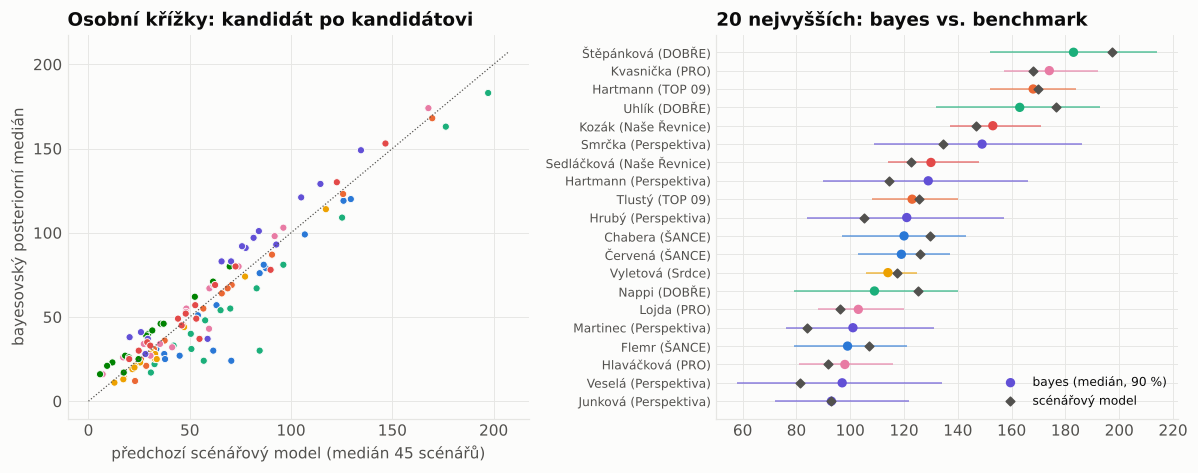

Korelace posteriorních mediánů s benchmarkem: 0.95; celkem benchmark 6 884 vs. bayes 6,878 [5,621; 8,202].


In [21]:
idata0 = fit_or_load("baseline_no_u", lambda: M.build_model(H, M.PriorConfig(n_valid_ballots=V_CITY, candidate_effects=False, local_effects=False)), **SUB_KW)
try:
    cmp = az.compare({"hlavní (u, v)": idata, "bez osobních efektů": idata0})
    display(cmp)
    cmp.to_csv(RES / "model_comparison_loo.csv")
except Exception as ex:
    print("az.compare selhalo:", ex)
for nm, idt in [("hlavní", idata), ("bez u, v", idata0)]:
    ll = idt.log_likelihood["H"].values
    print(f"{nm}: průměrná log-likelihood na tah = {ll.sum(axis=tuple(range(2, ll.ndim))).mean():.1f}")
mu0 = PO.stack_draws(idata0.posterior["mu"]).mean(0); mu1 = PO.stack_draws(post["mu"]).mean(0)
print(f"MAE (hlasy na kandidáta a okrsek): hlavní {np.abs(mu1 - H).mean():.2f}, bez osobních efektů {np.abs(mu0 - H).mean():.2f}")
fig = PL.fig_vs_baseline(tab); plt.show()
corr_b = np.corrcoef(tab.C_median, tab.baseline_median)[0, 1]
print(f"Korelace posteriorních mediánů s benchmarkem: {corr_b:.2f}; celkem benchmark 6 884 vs. bayes {tq[1]:,.0f} [{tq[0]:,.0f}; {tq[2]:,.0f}].")

### 8.8 Změny 2022 → 2026

V roce 2022 měly Řevnice **jen 2 okrsky**, takže okrsek 1 (2022) a okrsek 1 (2026) **nejsou totéž území** – srovnáváme pouze celoměstské hodnoty. Kandidátská data 2022 nejsou v balíčku po kandidátech, pouze pro zvolené zastupitele, kteří uspěli v obou volbách.

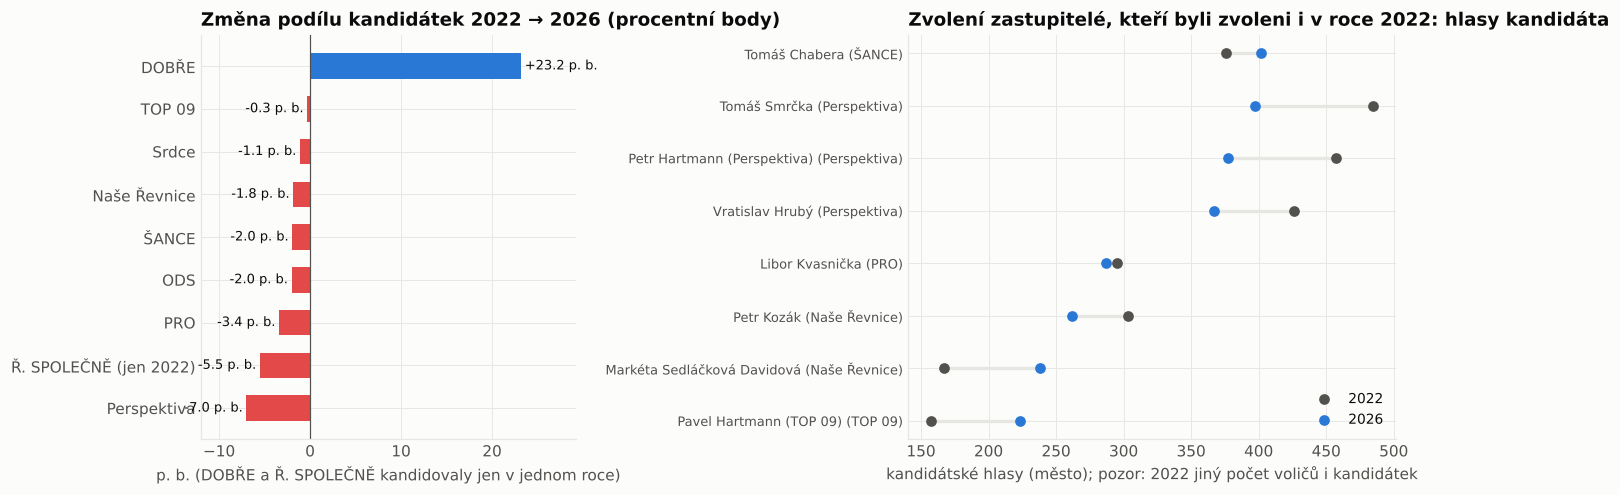

,zastupitel,strana_2026,hlasy_2026,poradi_na_kandidatce,hlasy_2022_pokud_zvolen_2022,strana_2022,zmena_hlasu,zmena_pct
0,Martina Štěpánková,DOBŘE - Dialog o budoucnosti Řevnic,512,1,NaN,NaN,NaN,NaN
1,Michal Uhlík,DOBŘE - Dialog o budoucnosti Řevnic,491,2,NaN,NaN,NaN,NaN
2,Martina Nappi Bursík,DOBŘE - Dialog o budoucnosti Řevnic,437,3,NaN,NaN,NaN,NaN
3,Vladimír Bobek,DOBŘE - Dialog o budoucnosti Řevnic,393,4,NaN,NaN,NaN,NaN
4,Tomáš Chabera,ŠANCE Řevnice,402,1,376.00,ŠANCE Řevnice,26.00,6.91
5,Terezie Červená,ŠANCE Řevnice,383,10,NaN,NaN,NaN,NaN
6,Lukáš Flemr,ŠANCE Řevnice,379,4,NaN,NaN,NaN,NaN
7,Tomáš Smrčka,Perspektiva pro město,397,1,485.00,Perspektiva pro město,-88.00,-18.14
8,Petr Hartmann (Perspektiva),Perspektiva pro město,377,2,457.00,Perspektiva pro město,-80.00,-17.51
9,Vratislav Hrubý,Perspektiva pro město,367,4,426.00,Perspektiva pro město,-59.00,-13.85


**Pravidlo 10 %:** kandidát se posune na čelo, má-li alespoň o 10 % více hlasů než průměr kandidátky. DOBŘE: průměr 370,2 → práh 407,2. Renata Dudová (5., 405 hlasů = +9,4 %) ani Vladimír Bobek (4., 393) práh nepřekročili, proto rozhodlo pořadí na kandidátce a mandát získal Bobek. ŠANCE: průměr 322,7 → práh 354,9; Terezie Červená (383) a Lukáš Flemr (379) práh překročili a přeskočili 2. a 3. místo kandidátky. Jde o **pozorované fakty** z pravidel, ne o výsledek modelu.

In [22]:
fig = PL.fig_changes_2022_2026(d); plt.show()
el = d.elected.copy()
display(el)
dob = tab[(tab.party_id == 3)].sort_values("position")[["position", "name", "votes_city", "elected", "C_median"]]
avg = dob.votes_city.mean()
display(Markdown(czfmt(f"**Pravidlo 10 %:** kandidát se posune na čelo, má-li alespoň o 10 % více hlasů než průměr kandidátky. DOBŘE: průměr {avg:.1f} → práh {1.1*avg:.1f}. Renata Dudová (5., 405 hlasů = {405/avg-1:+.1%}) ani Vladimír Bobek (4., 393) práh nepřekročili, proto rozhodlo pořadí na kandidátce a mandát získal Bobek. ŠANCE: průměr {tab[tab.party_id==1].votes_city.mean():.1f} → práh {1.1*tab[tab.party_id==1].votes_city.mean():.1f}; Terezie Červená (383) a Lukáš Flemr (379) práh překročili a přeskočili 2. a 3. místo kandidátky. Jde o **pozorované fakty** z pravidel, ne o výsledek modelu.")))

## 9. Interaktivní grafy (Plotly)

Interaktivní verze (hover s detaily, filtr strany, procházení kandidátů) se ukládají do `interactive/*.html` – otevřete je dvojklikem v prohlížeči, žádný server není potřeba (sdílená knihovna `interactive/plotly.min.js` se uloží vedle). GitHub `.ipynb` JavaScript nevykreslí, proto jsou všechny podstatné grafy výše uloženy také staticky do `figures/`. V živém Jupyteru se grafy zobrazí i zde.

In [23]:
import plotly.io as pio
pio.renderers.default = "plotly_mimetype"
S4_med = np.median(PO.stack_draws(post["S"]), axis=0)
figs = {
    "kandidati_posterior.html": PL.plotly_candidates(tab),
    "okrsky_heatmapa.html": PL.plotly_precinct_heatmap(d),
    "rozklad_strany.html": PL.plotly_decomposition(d, S_med, C_med, C_lo, C_hi),
    "prispevky_okrsku_kandidati.html": PL.plotly_candidate_browser(d, C_real, S4_med),
    "zmeny_2022_2026.html": PL.plotly_changes(d),
}
for name, f in figs.items():
    PL.save_plotly(f, name); print("uloženo", INTER / name)
figs["kandidati_posterior.html"].show()

uloženo /home/claude/revnice2026-bayes/interactive/kandidati_posterior.html
uloženo /home/claude/revnice2026-bayes/interactive/okrsky_heatmapa.html
uloženo /home/claude/revnice2026-bayes/interactive/rozklad_strany.html
uloženo /home/claude/revnice2026-bayes/interactive/prispevky_okrsku_kandidati.html
uloženo /home/claude/revnice2026-bayes/interactive/zmeny_2022_2026.html


In [24]:
figs["rozklad_strany.html"].show()
figs["prispevky_okrsku_kandidati.html"].show()

## 10. Souhrn zjištění běžnou češtinou

Každý bod je označen: **[fakt]** = pozorovaná hodnota z výsledků ČSÚ a pravidel; **[mez]** = rigorózní dolní mez odvozená jen z mechaniky sčítání; **[model]** = posteriorní odhad podmíněný modelem a priory (simulace v odd. 6 ukazují, že pořadí a osobní efekty jsou robustní, celkové součty jen přibližné).

In [25]:
rec_bias = rec_tab["total_med"] / rec_tab["total_true"] - 1
rec_bias_min, rec_bias_max = float(rec_bias.min()), float(rec_bias.max())
topu = tab.sort_values("u_median", ascending=False).head(8)
topC = tab.sort_values("C_median", ascending=False).head(8)
lowu = tab.sort_values("u_median").head(4)
pk0 = party_tab.set_index("party")["p_k0_median"]
precinct_share = prec_tab.set_index("precinct")["C_share_median"]
best_prec = prec_tab.sort_values("C_share_median", ascending=False).iloc[0]
pe = party_tab.sort_values("C_share_median", ascending=False)
nn = D.nice_name
sens_i = sens.set_index("label")
long_tail = sens_i.loc["ocas K: ratio 0,85 (dlouhý)"] if "ocas K: ratio 0,85 (dlouhý)" in sens_i.index else sens_i.iloc[0]
short_tail = sens_i.loc["ocas K: ratio 0,50 (krátký)"] if "ocas K: ratio 0,50 (krátký)" in sens_i.index else sens_i.iloc[0]
findings = f'''
1. **[fakt]** Řevnice 2026: 1 679 platných lístků, 23 939 kandidátských hlasů (14,26 hlasu na lístek); voliči nevyužili 1 246 hlasů – ty mohly vzniknout jen na lístcích bez označené strany. DOBŘE (nová kandidátka) vyhrálo s 23,2 % a 4 mandáty, Perspektiva ztratila 7,0 p. b. a ODS chybělo **15 hlasů = jeden stranický lístek** k překročení 5% klauzule; Srdce Řevnic chybělo 95 hlasů.
2. **[mez]** Bez jakéhokoli modelu lze dokázat, že individuálních křížků bylo nejméně **{LB_LP:,}** ({LB_LP/23939:.1%} hlasů) – díky zákonu zachování (lístek se stranou = přesně 15 hlasů) je to téměř dvojnásobek prostého součtu monotónních mezí (1 493; z městských součtů jen 1 096). Jen lídři kandidátek museli dostat dohromady nejméně {int(pos_sum[:, 0].sum())} individuálních křížků.
3. **[model]** Model odhaduje celkem **{tq[1]:,.0f}** identifikovatelných osobních křížků (90 %: {tq[0]:,.0f}–{tq[2]:,.0f}; {tq[1]/23939:.0%} hlasů); citlivostní varianty dávají mediány {sens.total_C_median.min():,.0f}–{sens.total_C_median.max():,.0f} (scénářové rozpětí). Starší nebayesovský scénářový model dával 6 884 (28,8 %) – {"číselná shoda je do značné míry náhoda dvou zcela odlišných metod" if abs(tq[1] - 6884) < 500 else "rozdíl je metodický (zachování hlasů, saturace, okrsková data)"}. V simulacích se známou pravdou se celkový součet obnovil s chybou {rec_bias_min:+.0%} až {rec_bias_max:+.0%}, takže skutečný počet může být vyšší o rovnoměrně rozprostřené křížky, které jsou od stranických lístků v agregátech nerozlišitelné.
4. **[model]** Přibližně **{pk0.mean():.0%}** lístků s označenou stranou nemá žádný křížek jinde (P(K=0), rozpětí podle kandidátek {pk0.min():.0%}–{pk0.max():.0%}); průměrně připadá na takový lístek E[K] ≈ {np.median(EKw):.1f} křížku u jiných stran. Lístků bez strany model odhaduje {Mq[1]:,.0f} ({Mq[1]/V_CITY:.0%} lístků, 90 %: {Mq[0]:,.0f}–{Mq[2]:,.0f}) s průměrem {mbq[1]:.0f} křížků. Tento rozklad je **slabě identifikovaný**: prior pro m̄ ho překvapivě nemění (data m̄ určují uvnitř modelu), ale předpoklad o ocasu rozdělení K ano – s dlouhým ocasem (poměr 0,85) klesá odhad celkových křížků na {long_tail['total_C_median']:,.0f} a křížků z lístků bez strany na {long_tail['R_median']:,.0f}, s krátkým ocasem (0,50) roste na {short_tail['total_C_median']:,.0f}.
5. **[model] Osobnosti voleb** (největší osobní efekt u po očištění o pozici, stranu a okrsek): {"; ".join(f"{nn(r['name'])} ({r['party']} {r['position']}., u = {r['u_median']:+.2f})" for _, r in topu.iterrows())}. Nejvíce osobních křížků v absolutním počtu (pomáhá jim pozice lídra): {"; ".join(f"{nn(r['name'])} ({r['party']}) ≈ {r['C_median']:.0f}" for _, r in topC.head(5).iterrows())}. Lídři nejsou automaticky osobnosti: {"; ".join(f"{nn(r['name'])} ({r['party']}) u = {r['u_median']:+.2f}" for _, r in tab[tab.position == 1].sort_values("u_median").head(3).iterrows())} dostávají méně křížků, než by lídr jejich strany „měl“.
6. **[mez + model] Terezie Červená** (ŠANCE, 10.): prokazatelně nejméně {cz.lb_precinct_sum} individuálních křížků (po okrscích 17+21+28+22 – stabilně ve všech čtyřech, nejde o lokální efekt), model odhaduje {cz.C_median:.0f} [{cz.C_q05:.0f}; {cz.C_q95:.0f}] ({cz.C_share_median:.0%} jejích hlasů); osobní efekt u = {cz.u_median:+.2f} patří k nejvyšším v celém městě (pořadí podle křížků {cz.rank_median:.0f}, 90 %: {cz.rank_q05:.0f}–{cz.rank_q95:.0f}). Přeskočila 8 kandidátů a získala mandát díky pravidlu 10 % **[fakt]**.
7. **[model] Přední místa vs. nižší pořadí:** sklon výhody pozice β ≈ {float(post["beta"].median()):.2f} [{float(post["beta"].quantile(0.05)):.2f}; {float(post["beta"].quantile(0.95)):.2f}] znamená, že kandidát na 15. místě dostává při jinak stejné popularitě jen ≈ {15**(-float(post["beta"].median())):.0%} křížků lídra; velká část poklesu hlasů na konci kandidátek je ale **mechanická** (odečítání zdola podle K), nikoli projev nezájmu o konkrétní lidi. Lídři dostávají typicky {np.median(tab[tab.position==1].C_share_median):.0%} svých hlasů z osobních křížků (medián přes 8 lídrů; u lídrů velkých kandidátek méně: Štěpánková {tab[(tab.party_id==3)&(tab.position==1)].C_share_median.iloc[0]:.0%}, Chabera {tab[(tab.party_id==1)&(tab.position==1)].C_share_median.iloc[0]:.0%}), kandidáti na 11.–15. místě ≈ {np.median(tab[tab.position>=11].C_share_median):.0%}.
8. **[model] Kandidátky:** nejvyšší podíl osobních křížků na hlasech mají {pe.iloc[0]["party"]} ({pe.iloc[0]["C_share_median"]:.0%}) a {pe.iloc[1]["party"]} ({pe.iloc[1]["C_share_median"]:.0%}), nejnižší {pe.iloc[-1]["party"]} ({pe.iloc[-1]["C_share_median"]:.0%}) – velké kandidátky s plochým profilem (DOBŘE) žijí hlavně ze stranických lístků, malé kandidátky z osobností. Pozor: podíl křížků u malé strany může být tažen několika lidmi (např. Masner, Hartmann u TOP 09; Cvanciger, Černý u ODS).
9. **[model] Okrsky:** podíl osobních křížků se mezi okrsky liší jen mírně ({", ".join(f"okrsek {int(k)}: {v:.0%}" for k, v in precinct_share.items())}); nejvíce „křížkuje“ okrsek {int(best_prec['precinct'])}. Okrsková data zpřesnila rigorózní meze (1 096 → 1 493, LP {int(np.ceil(lp_city['min_total_C'])):,} → {LB_LP:,}) a umožnila oddělit lokální výkyvy od konzistentní osobní popularity; LOPO (n = 4) ukazuje, že osobní efekty naučené na třech okrscích {"zlepšují" if lopo_tab["mae_model s u"].mean() < lopo_tab["mae_model bez u"].mean() else "nezlepšují"} predikci čtvrtého oproti modelu bez nich (MAE {lopo_tab["mae_model s u"].mean():.1f} vs. {lopo_tab["mae_model bez u"].mean():.1f} hlasu na kandidáta), ale {"ne" if lopo_tab["mae_model s u"].mean() >= lopo_tab["mae_naivní podíly"].mean() - 0.05 else "jen mírně"} oproti naivnímu prediktoru „podíly kandidátů v ostatních okrscích“ (MAE {lopo_tab["mae_naivní podíly"].mean():.1f}; model má lepší log-skóre {lopo_tab["lpd_model s u"].mean():.0f} vs. {lopo_tab["lpd_naivní podíly"].mean():.0f}) – přidaná hodnota modelu je v rozkladu hlasů, ne v predikci.
10. **[fakt] Překvapení pravidel:** Renata Dudová (DOBŘE, 5.) měla 405 hlasů – více než zvolený Vladimír Bobek (393) – ale nedosáhla 10 % nad průměr kandidátky, a mandát proto rozhodlo pořadí na lístku. Model jí přisuzuje {tab[(tab.party_id==3)&(tab.position==5)].C_median.iloc[0]:.0f} osobních křížků [{tab[(tab.party_id==3)&(tab.position==5)].C_q05.iloc[0]:.0f}; {tab[(tab.party_id==3)&(tab.position==5)].C_q95.iloc[0]:.0f}] (minimum {tab[(tab.party_id==3)&(tab.position==5)].lb_precinct_sum.iloc[0]}) **[model]**.
11. **[fakt] 2022 → 2026:** účast vzrostla z 56,1 % na 60,0 % a hlasů přibylo o 9,95 %; přesto lídři Perspektivy ztratili osobně (Smrčka 485 → 397, P. Hartmann 457 → 377, Hrubý 426 → 367), zatímco Pavel Hartmann (TOP 09, 157 → 223) a Markéta Sedláčková Davidová (ODS → Naše Řevnice, 167 → 238) výrazně posílili. Model řadí oba mezi osobnosti s vysokým u **[model]**. Porovnání okrsků 2022/2026 není možné (jiné členění).
12. **[model] Co je nestabilní:** u {int((tab.robust_rank=="nestabilní").sum())} ze 120 kandidátů má 90% interval posteriorního pořadí šířku přes 40 míst – typicky kandidáti na nižších místech velkých kandidátek, kde několik křížků nelze odlišit od šumu stranických lístků. Kandidáti s nejslabším osobním efektem: {"; ".join(f"{nn(r['name'])} ({r['party']} {r['position']}.)" for _, r in lowu.iterrows())} – u nich jsou hlasy téměř čistě stranické.
13. **Co stále nelze zjistit:** přesný počet lístků bez strany a jejich průměrný počet křížků (m̄), tedy ani přesný celkový počet křížků; zda konkrétní křížek pochází od voliče jiné strany nebo od voliče bez strany; a cokoli o jednotlivých lístcích. Nejvíce by pomohly **počty platných lístků po okrscích** (ČSÚ je publikuje; v balíčku chybí) a případné anonymní povolební dotazování o počtu křížků – obojí lze do modelu přidat beze změny struktury.
'''
findings = czfmt(findings)
display(Markdown(findings))
open(RES / "souhrn_zjisteni.md", "w", encoding="utf-8").write(findings)


1. **[fakt]** Řevnice 2026: 1 679 platných lístků, 23 939 kandidátských hlasů (14,26 hlasu na lístek); voliči nevyužili 1 246 hlasů – ty mohly vzniknout jen na lístcích bez označené strany. DOBŘE (nová kandidátka) vyhrálo s 23,2 % a 4 mandáty, Perspektiva ztratila 7,0 p. b. a ODS chybělo **15 hlasů = jeden stranický lístek** k překročení 5% klauzule; Srdce Řevnic chybělo 95 hlasů.
2. **[mez]** Bez jakéhokoli modelu lze dokázat, že individuálních křížků bylo nejméně **2 890** (12,1 % hlasů) – díky zákonu zachování (lístek se stranou = přesně 15 hlasů) je to téměř dvojnásobek prostého součtu monotónních mezí (1 493; z městských součtů jen 1 096). Jen lídři kandidátek museli dostat dohromady nejméně 706 individuálních křížků.
3. **[model]** Model odhaduje celkem **6 878** identifikovatelných osobních křížků (90 %: 5 621–8 202; 29 % hlasů); citlivostní varianty dávají mediány 5 075–7 729 (scénářové rozpětí). Starší nebayesovský scénářový model dával 6 884 (28,8 %) – číselná shoda je do značné míry náhoda dvou zcela odlišných metod. V simulacích se známou pravdou se celkový součet obnovil s chybou -22 % až +15 %, takže skutečný počet může být vyšší o rovnoměrně rozprostřené křížky, které jsou od stranických lístků v agregátech nerozlišitelné.
4. **[model]** Přibližně **76 %** lístků s označenou stranou nemá žádný křížek jinde (P(K=0), rozpětí podle kandidátek 75 %–78 %); průměrně připadá na takový lístek E[K] ≈ 1,0 křížku u jiných stran. Lístků bez strany model odhaduje 462 (28 % lístků, 90 %: 332–574) s průměrem 12 křížků. Tento rozklad je **slabě identifikovaný**: prior pro m̄ ho překvapivě nemění (data m̄ určují uvnitř modelu), ale předpoklad o ocasu rozdělení K ano – s dlouhým ocasem (poměr 0,85) klesá odhad celkových křížků na 5 564 a křížků z lístků bez strany na 2 888, s krátkým ocasem (0,50) roste na 7 729.
5. **[model] Osobnosti voleb** (největší osobní efekt u po očištění o pozici, stranu a okrsek): Terezie Červená (ŠANCE 10., u = +1,12); Ondřej Masner (TOP 09 12., u = +0,96); Miroslav Cvanciger (ODS 7., u = +0,83); Barbora Ciglerová (Naše Řevnice 14., u = +0,80); Ivana Junková (Perspektiva 13., u = +0,68); Jan Lojda (PRO 6., u = +0,64); Pavel Hartmann (TOP 09 2., u = +0,62); Šimon Martinec (Perspektiva 10., u = +0,61). Nejvíce osobních křížků v absolutním počtu (pomáhá jim pozice lídra): Martina Štěpánková (DOBŘE) ≈ 183; Libor Kvasnička (PRO) ≈ 174; Pavel Hartmann (TOP 09) ≈ 168; Michal Uhlík (DOBŘE) ≈ 163; Petr Kozák (Naše Řevnice) ≈ 153. Lídři nejsou automaticky osobnosti: Anna Schlindenbuch (ODS) u = -0,53; Tomáš Smrčka (Perspektiva) u = -0,31; Tomáš Chabera (ŠANCE) u = -0,19 dostávají méně křížků, než by lídr jejich strany „měl“.
6. **[mez + model] Terezie Červená** (ŠANCE, 10.): prokazatelně nejméně 88 individuálních křížků (po okrscích 17+21+28+22 – stabilně ve všech čtyřech, nejde o lokální efekt), model odhaduje 119 [103; 137] (31 % jejích hlasů); osobní efekt u = +1,12 patří k nejvyšším v celém městě (pořadí podle křížků 11, 90 %: 7–18). Přeskočila 8 kandidátů a získala mandát díky pravidlu 10 % **[fakt]**.
7. **[model] Přední místa vs. nižší pořadí:** sklon výhody pozice β ≈ 0,63 [0,51; 0,77] znamená, že kandidát na 15. místě dostává při jinak stejné popularitě jen ≈ 18 % křížků lídra; velká část poklesu hlasů na konci kandidátek je ale **mechanická** (odečítání zdola podle K), nikoli projev nezájmu o konkrétní lidi. Lídři dostávají typicky 59 % svých hlasů z osobních křížků (medián přes 8 lídrů; u lídrů velkých kandidátek méně: Štěpánková 36 %, Chabera 30 %), kandidáti na 11.–15. místě ≈ 26 %.
8. **[model] Kandidátky:** nejvyšší podíl osobních křížků na hlasech mají TOP 09 (53 %) a ODS (49 %), nejnižší DOBŘE (17 %) – velké kandidátky s plochým profilem (DOBŘE) žijí hlavně ze stranických lístků, malé kandidátky z osobností. Pozor: podíl křížků u malé strany může být tažen několika lidmi (např. Masner, Hartmann u TOP 09; Cvanciger, Černý u ODS).
9. **[model] Okrsky:** podíl osobních křížků se mezi okrsky liší jen mírně (okrsek 1: 27 %, okrsek 2: 32 %, okrsek 3: 30 %, okrsek 4: 26 %); nejvíce „křížkuje“ okrsek 2. Okrsková data zpřesnila rigorózní meze (1 096 → 1 493, LP 2 529 → 2 890) a umožnila oddělit lokální výkyvy od konzistentní osobní popularity; LOPO (n = 4) ukazuje, že osobní efekty naučené na třech okrscích zlepšují predikci čtvrtého oproti modelu bez nich (MAE 4,1 vs. 5,2 hlasu na kandidáta), ale ne oproti naivnímu prediktoru „podíly kandidátů v ostatních okrscích“ (MAE 4,1; model má lepší log-skóre -388 vs. -396) – přidaná hodnota modelu je v rozkladu hlasů, ne v predikci.
10. **[fakt] Překvapení pravidel:** Renata Dudová (DOBŘE, 5.) měla 405 hlasů – více než zvolený Vladimír Bobek (393) – ale nedosáhla 10 % nad průměr kandidátky, a mandát proto rozhodlo pořadí na lístku. Model jí přisuzuje 81 osobních křížků [56; 109] (minimum 13) **[model]**.
11. **[fakt] 2022 → 2026:** účast vzrostla z 56,1 % na 60,0 % a hlasů přibylo o 9,95 %; přesto lídři Perspektivy ztratili osobně (Smrčka 485 → 397, P. Hartmann 457 → 377, Hrubý 426 → 367), zatímco Pavel Hartmann (TOP 09, 157 → 223) a Markéta Sedláčková Davidová (ODS → Naše Řevnice, 167 → 238) výrazně posílili. Model řadí oba mezi osobnosti s vysokým u **[model]**. Porovnání okrsků 2022/2026 není možné (jiné členění).
12. **[model] Co je nestabilní:** u 28 ze 120 kandidátů má 90% interval posteriorního pořadí šířku přes 40 míst – typicky kandidáti na nižších místech velkých kandidátek, kde několik křížků nelze odlišit od šumu stranických lístků. Kandidáti s nejslabším osobním efektem: Matěj Krofta (PRO 10.); Renáta Foldynová (ŠANCE 5.); Tomáš Brodský (TOP 09 15.); Anna Schlindenbuch (ODS 1.) – u nich jsou hlasy téměř čistě stranické.
13. **Co stále nelze zjistit:** přesný počet lístků bez strany a jejich průměrný počet křížků (m̄), tedy ani přesný celkový počet křížků; zda konkrétní křížek pochází od voliče jiné strany nebo od voliče bez strany; a cokoli o jednotlivých lístcích. Nejvíce by pomohly **počty platných lístků po okrscích** (ČSÚ je publikuje; v balíčku chybí) a případné anonymní povolební dotazování o počtu křížků – obojí lze do modelu přidat beze změny struktury.


6156

## 11. Limity, poctivost a reprodukovatelnost

* **Ekologická inference má meze** (Tam Cho & Gaines 2004): různé rozdělení lístků může dát totožné agregáty. Náš model to nepřekonává – jen explicitně říká, které předpoklady identifikaci dodávají (hierarchie napříč okrsky, zachování hlasů, prior $\bar m$, tvar výhody pozice), a simulací ukazuje, co z toho plyne: pořadí a osobní efekty jsou robustní, celkové součty jsou slabě identifikované a spíše podhodnocené.
* **Čtyři okrsky nejsou 480 nezávislých pozorování** lístků; ESS, R̂ i PPC se týkají modelu, ne reality.
* **Posteriorní intervaly nejsou „změřené“ křížky ČSÚ**; realizované počty jsou podmíněné aproximací a oříznuté dokazatelnými mezemi.
* **Co by analýzu nejvíce zpřesnilo:** platné lístky po okrscích (4 čísla), kalibrace $\bar m$ a $P(K=0)$ z anonymního dotazování nebo z obcí, kde ČSÚ zveřejnila typologii lístků.
* **Reprodukovatelnost:** pevné seedy, připnuté verze (`requirements.txt`), všechny fity ukládány do `fits/`, tabulky do `results/`, grafy do `figures/` a `interactive/`. Primární data: ČSÚ / volby.gov.cz (uživatelské exporty v `data/raw/`), počet platných lístků z `vysledky_obec_539643.xml` (ČSÚ open data, 10. 10. 2026 19:12).

In [26]:
runtime = {"sampling_time_main_s": float(idata.sample_stats.attrs.get("sampling_time", np.nan)), "divergences_main": PO.n_divergences(idata),
           "versions": {"python": sys.version.split()[0], "pymc": pm.__version__, "arviz": az.__version__, "pytensor": pytensor.__version__, "numpy": np.__version__, "pandas": pd.__version__},
           "FAST": FAST, "USE_CACHE": USE_CACHE, "seed": SEED, "n_free_params": int(n_free)}
json.dump(runtime, open(RES / "run_info.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(runtime, indent=2, ensure_ascii=False))
print("Soubory v results/:", sorted(p.name for p in RES.iterdir()))
print("Soubory ve figures/:", sorted(p.name for p in FIG.iterdir()))
print("Soubory v interactive/:", sorted(p.name for p in INTER.iterdir()))

{
  "sampling_time_main_s": 526.9306240081787,
  "divergences_main": 1,
  "versions": {
    "python": "3.13.16",
    "pymc": "6.3.2",
    "arviz": "1.3.0",
    "pytensor": "3.3.3",
    "numpy": "2.5.3",
    "pandas": "3.0.5"
  },
  "FAST": false,
  "USE_CACHE": false,
  "seed": 20261010,
  "n_free_params": 834
}
Soubory v results/: ['candidate_estimates.csv', 'lopo.csv', 'mcmc_diagnostics_main.csv', 'mcmc_summary_main.csv', 'model_comparison_loo.csv', 'party_estimates.csv', 'ppc_residuals.csv', 'precinct_estimates.csv', 'prior_config_main.json', 'recovery_A_malo_krizku.csv', 'recovery_B_hodne_krizku.csv', 'recovery_D_ruzne_strany.csv', 'rigorous_bounds_candidates.csv', 'rigorous_bounds_precincts.csv', 'run_info.json', 'runtime_log.json', 'sensitivity.csv', 'souhrn_zjisteni.md']
Soubory ve figures/: ['fig01_strany_hlasy_mandaty.png', 'fig02_heatmapa_okrsky.png', 'fig03_distribuce_kandidatu.png', 'fig04_posterior_zebricek.png', 'fig04b_osobni_efekt_u.png', 'fig05_rozklad_strana_vs_indivi